In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_countries_win6 = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [3]:
one_point_countries_win6.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Delete countries that represent most outliers in house price index

In [4]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [5]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [6]:
one_point_countries_win6 = remove_rows_by_countries(one_point_countries_win6, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


### Apply PCA

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
pca_input = one_point_countries_win6.select_dtypes(include='number')

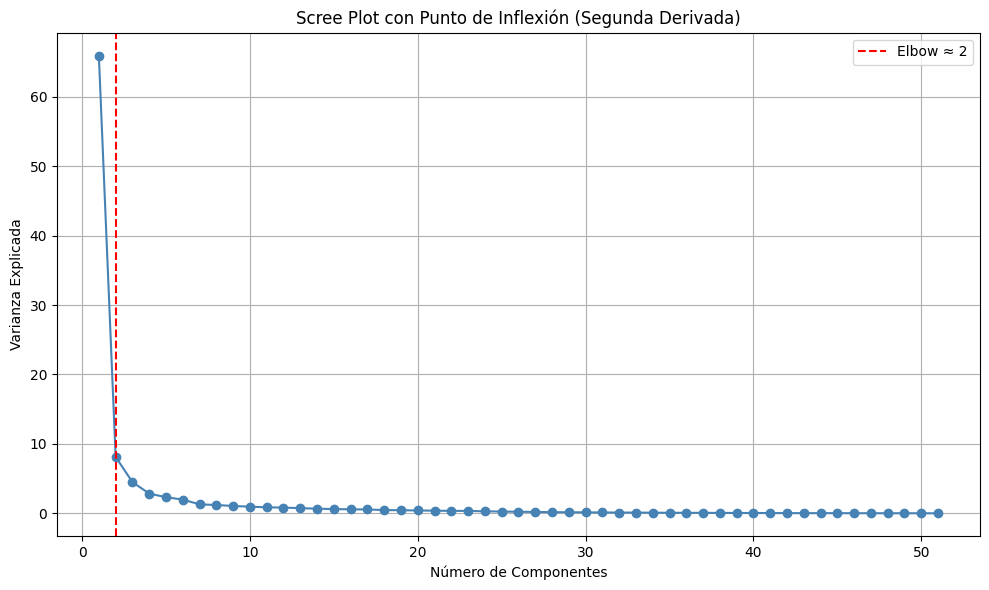

Punto de inflexión sugerido por segunda derivada: 2


In [9]:
# PCA completo
pca_full = PCA()
pca_full.fit(pca_input)

# Varianza explicada
explained_var = pca_full.explained_variance_ratio_

# Segunda derivada
second_derivative = np.diff(explained_var, n=2)
elbow_point = np.argmax(second_derivative) + 2  # +2 para alinear con el número de componentes

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var * 100, marker='o', linestyle='-', color='steelblue')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot con Punto de Inflexión (Segunda Derivada)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Imprimir punto de inflexión
print(f"Punto de inflexión sugerido por segunda derivada: {elbow_point}")

In [10]:
explained_var

array([6.59113735e-01, 8.12661210e-02, 4.49879321e-02, 2.84519529e-02,
       2.32369553e-02, 1.98396342e-02, 1.29309674e-02, 1.20439825e-02,
       1.05964636e-02, 9.61927349e-03, 8.68119499e-03, 8.26776248e-03,
       7.54372740e-03, 6.67556018e-03, 6.16317632e-03, 5.77365542e-03,
       5.59535500e-03, 4.66912672e-03, 4.48799448e-03, 4.12597217e-03,
       3.83086001e-03, 3.56247058e-03, 3.50406642e-03, 2.94017400e-03,
       2.58075751e-03, 2.30309034e-03, 2.05361143e-03, 1.65589541e-03,
       1.56471516e-03, 1.39266987e-03, 1.30232840e-03, 1.14819994e-03,
       1.10323711e-03, 9.17770864e-04, 8.18903470e-04, 7.50527951e-04,
       6.90405215e-04, 6.14938635e-04, 5.36829169e-04, 4.77448781e-04,
       3.95580217e-04, 3.18665700e-04, 2.81279849e-04, 2.51272919e-04,
       2.46486126e-04, 1.77762861e-04, 1.56761940e-04, 1.28587364e-04,
       1.22145946e-04, 1.02013823e-04, 1.29987264e-31])

In [11]:
pca_2 = PCA(n_components=2)

In [12]:
countries_win6_pca = pca_2.fit_transform(pca_input)

In [13]:
pca_df = pd.DataFrame(countries_win6_pca, columns=['PC1', 'PC2'])

In [14]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [15]:
print(pca_2.explained_variance_ratio_)
print(pca_2.explained_variance_ratio_.sum())

[0.65911374 0.08126612]
0.7403798562035435


In [16]:
sum_var_expl_sum = round(float(pca_2.explained_variance_ratio_.sum()),2)

In [17]:
tuple_var_expl_pca = (round(float(pca_2.explained_variance_ratio_[0]),2), round(float(pca_2.explained_variance_ratio_[1]),2))

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [18]:
from sklearn.cluster import KMeans

In [19]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [20]:
pca_df.shape

(51, 2)

#### Using the elbow method to find the optimal number of clusters

In [21]:
import time

In [22]:
distortions = []
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]

KMeans algorithm:
- n_clusters: Specifies the number of clusters to form. It directly determines the granularity of the grouping.
- init: Defines the method for initializing centroids. 'k-means++' is preferred for better convergence.
- n_init: Sets how many times the algorithm runs with different centroid seeds. Higher values improve robustness.
- max_iter: Limits the number of iterations per run. Controls convergence depth.
- tol: Sets the tolerance for declaring convergence. Affects when the algorithm stops based on centroid movement.
- random_state: Fixes the seed for reproducibility. Ensures consistent results across runs.
- algorithm: Chooses the internal algorithm variant ('lloyd' or 'elkan'). 'elkan' is faster for well-separated clusters.



Running elbow plots for random_state=21


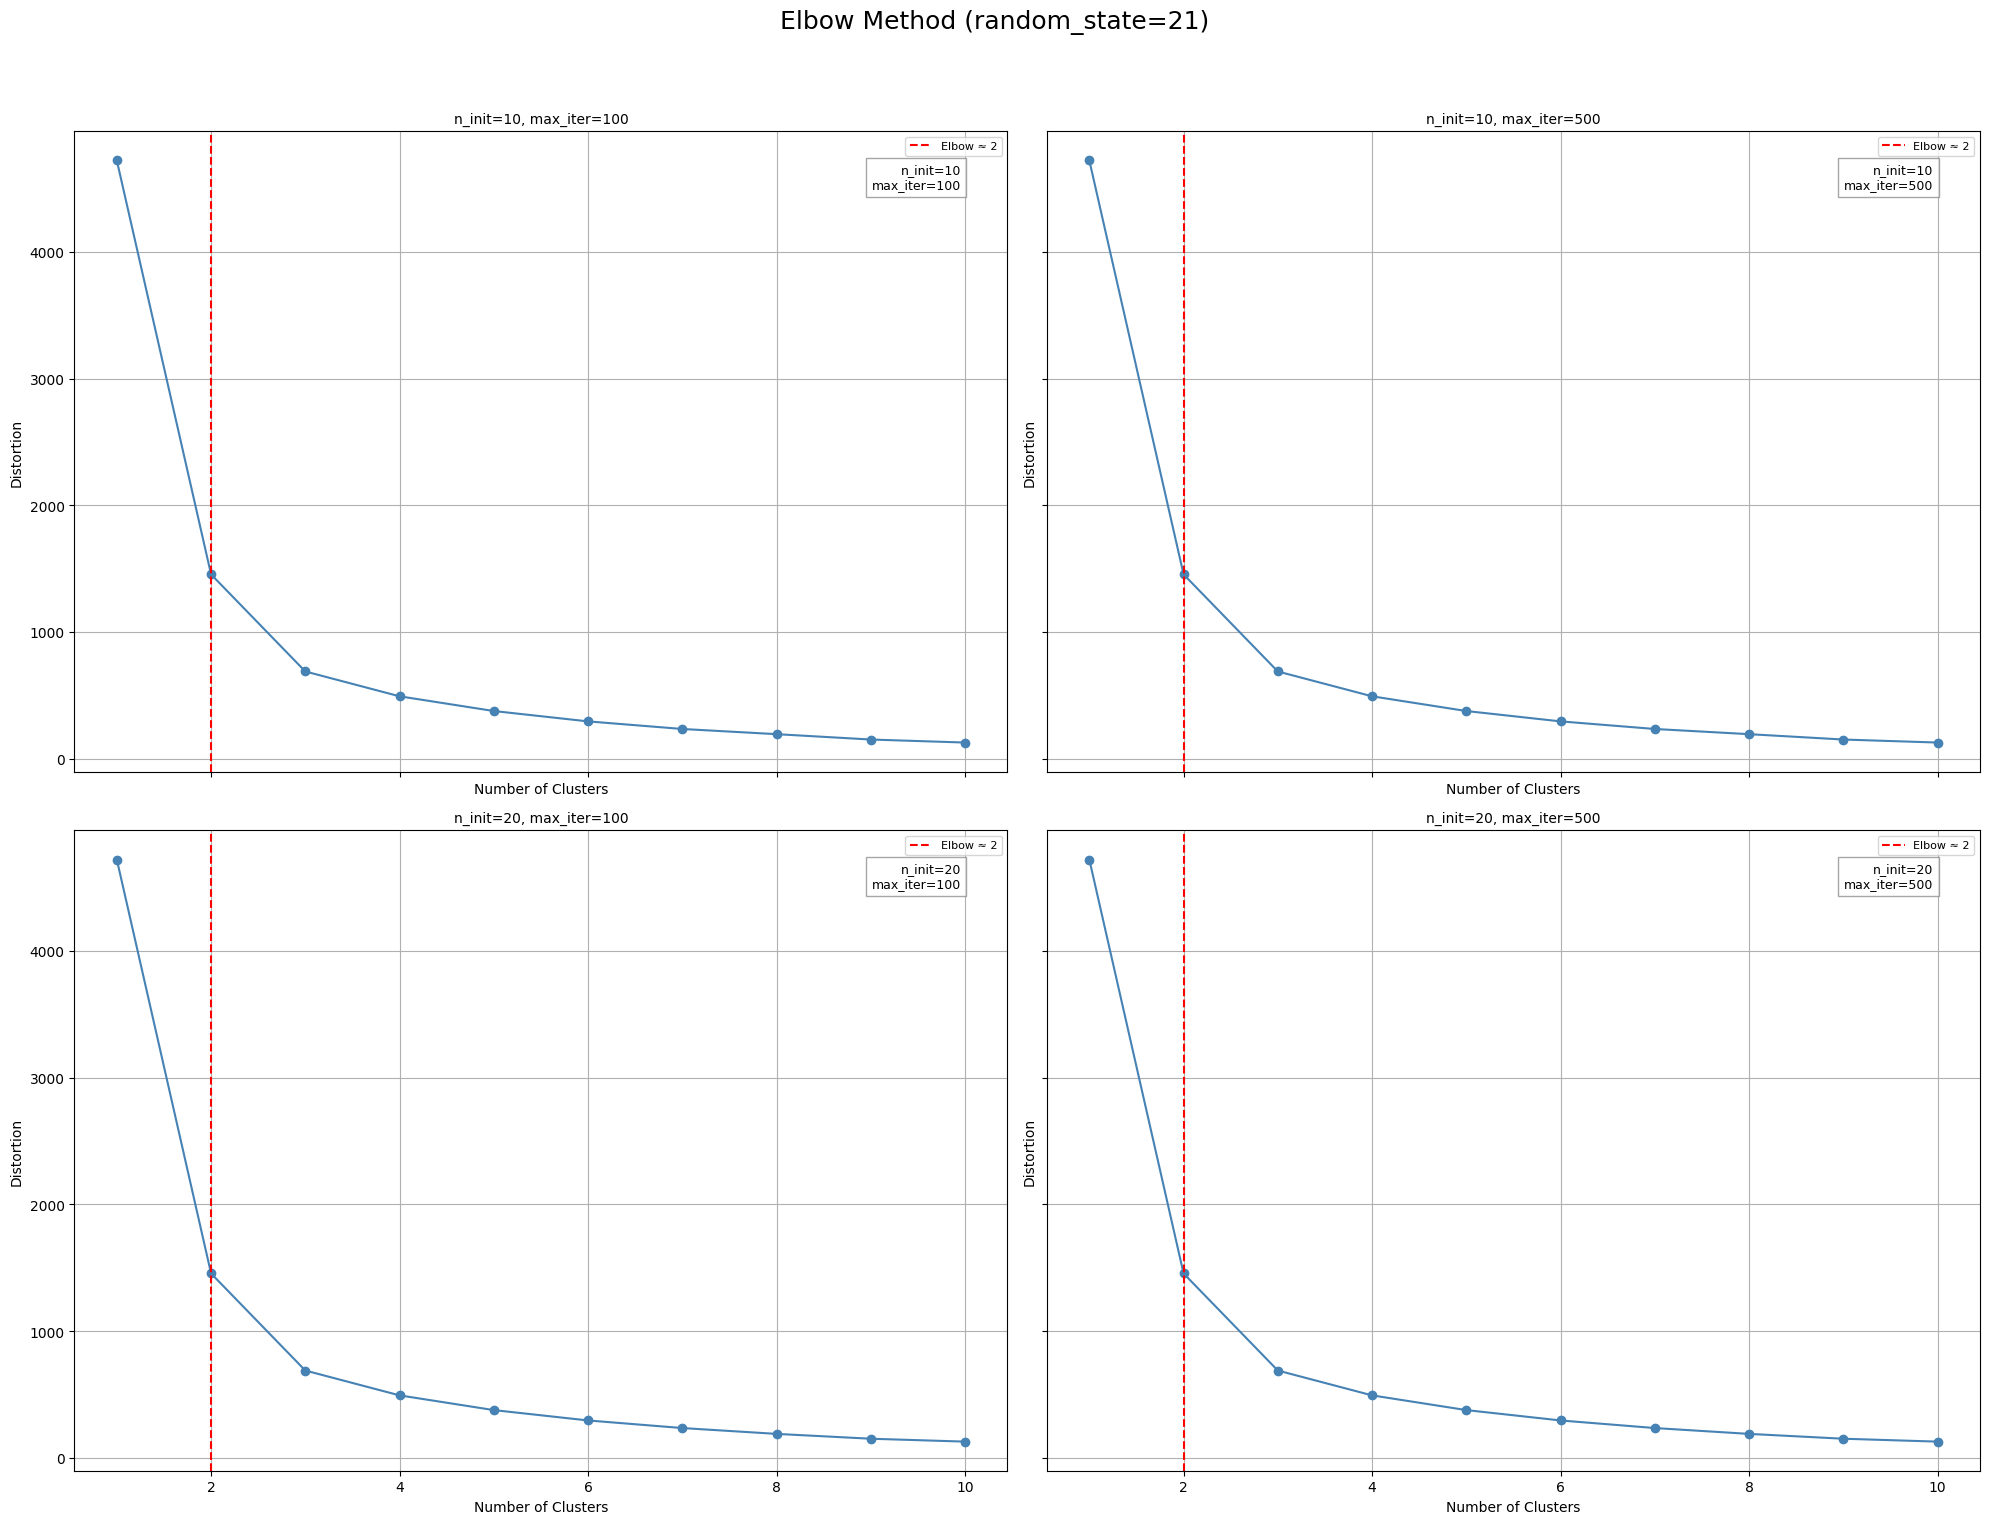


Running elbow plots for random_state=42


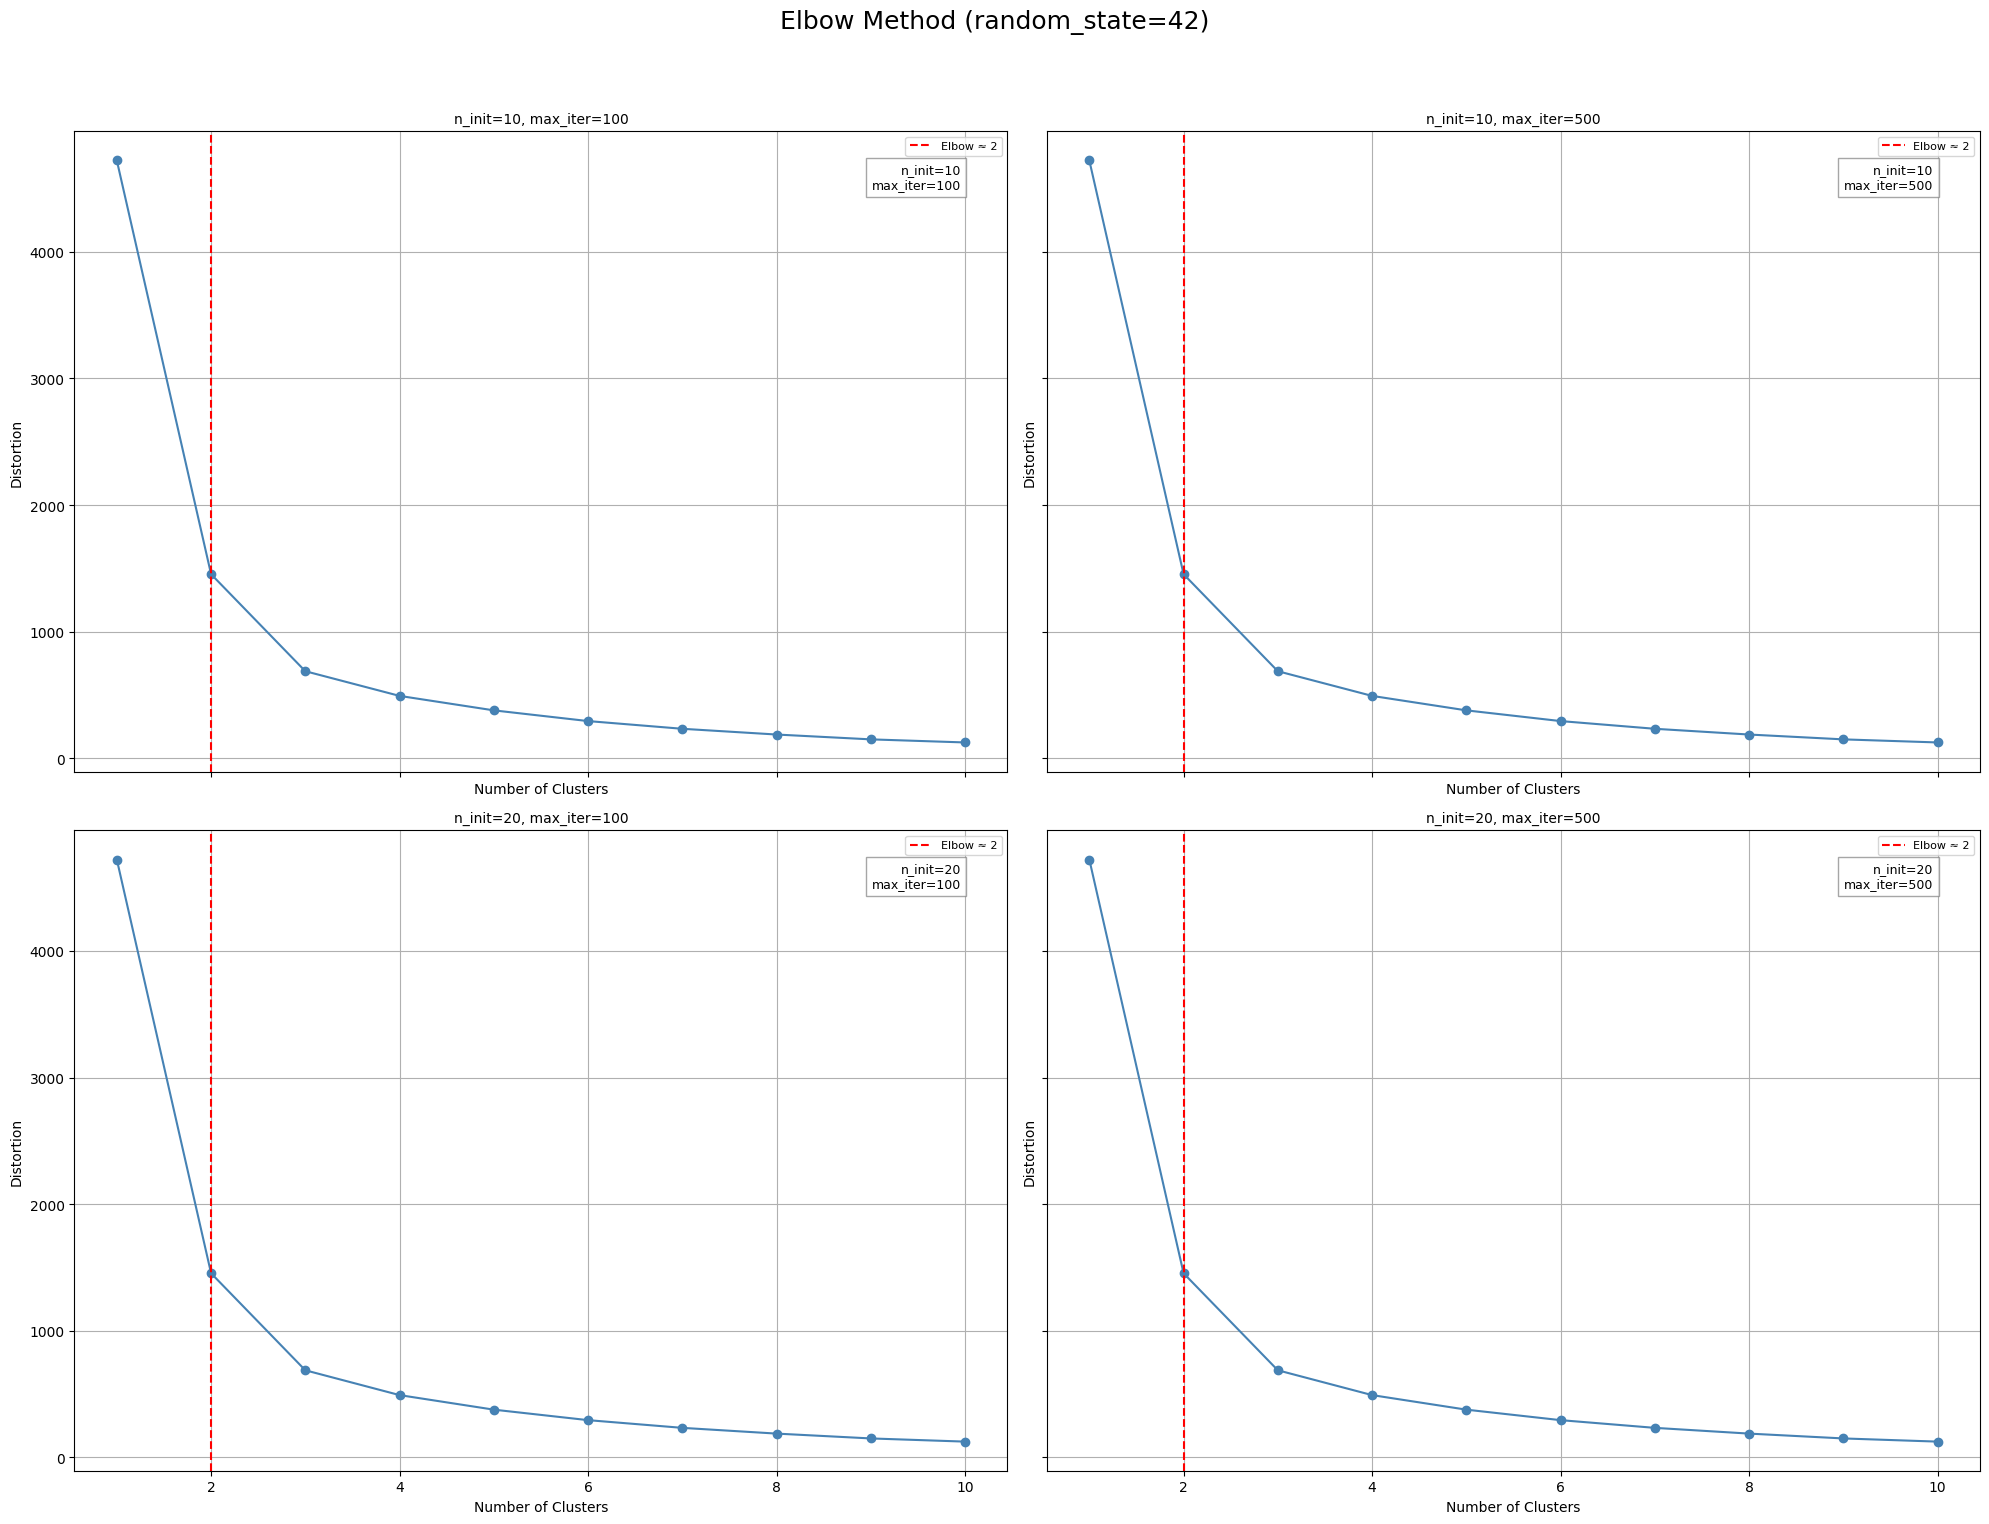


Total execution time: 7.32 seconds


In [23]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(pca_df)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* Compared to the "parent" experiment from which this one evolves, the distortions achieved with a two-cluster configuration give a much better result.

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [24]:
from sklearn.metrics import silhouette_samples

In [25]:
from matplotlib import cm

In [26]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [27]:
km_c2_ni20_maxi500_pca2 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [28]:
ym_c2_ni20_maxi500_pca2 = km_c2_ni20_maxi500_pca2.fit(pca_df)

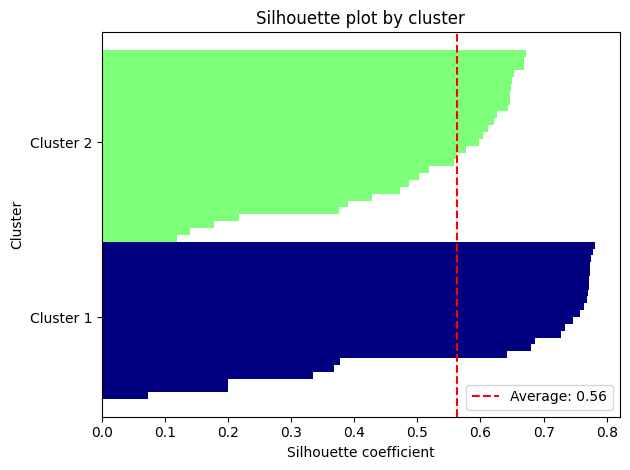

In [29]:
silhoutte_score_pca2 = plot_silhouette(ym_c2_ni20_maxi500_pca2, pca_df)

1. Uniform height on the Y axis
- Each row represents a cluster.
- Height ≠ quality, but if all clusters have a similar number of samples, the bars should have similar heights.
- If you see a very thin cluster (low height), it may indicate that the group has too few elements → possible outlier or oversegmentation.

2. Length of the bars on the X-axis
- This does indicate quality: it is the Silhouette Coefficient of each point.
- Values ​​close to +1 → the point is correctly assigned to its cluster.
- Values ​​close to 0 → the point is on the border between clusters.
- Negative values ​​→ the point is probably incorrectly assigned.

In [30]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [31]:
pca_df.shape

(51, 2)

In [32]:
one_point_countries_win6.shape

(51, 189)

In [33]:
ym_c2_ni20_maxi500_pca2.labels_

array([1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 1, 1, 1], dtype=int32)

In [34]:
final_pca2 = pca_df.copy()
final_pca2['cluster'] = ym_c2_ni20_maxi500_pca2.labels_
final_pca2.head()

,PC1,PC2,cluster
0,2.064226,1.489614,1
1,-7.648769,0.995875,0
2,-6.580014,0.441960,0
3,9.370254,-1.189187,1
4,-10.818940,-1.642285,0


In [35]:
final_pca2

,PC1,PC2,cluster
0,2.064226,1.489614,1
1,-7.648769,0.995875,0
2,-6.580014,0.441960,0
3,9.370254,-1.189187,1
4,-10.818940,-1.642285,0
5,3.698850,2.479485,1
6,11.313440,-3.520124,1
7,12.057846,-5.641059,1
8,-12.115571,-2.024072,0
9,-12.524878,-1.895969,0


In [36]:
one_point_countries_win6 = one_point_countries_win6.reset_index()

In [37]:
final_pca2['Country'] = one_point_countries_win6.Country

In [38]:
import country_converter as coco

In [39]:
final_pca2['ISO_A3'] = coco.convert(names=final_pca2['Country'], to='ISO3')

In [40]:
final_pca2.loc[:, 'Continent'] = coco.convert(
    names=final_pca2['Country'], to='continent'
)

In [41]:
final_pca2['UNregion'] = coco.convert(names=final_pca2['Country'], to='UNregion')

In [42]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [43]:
print_cluster_groups(final_pca2)


🌍 Cluster 0 (23 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Switzerland (Europe)

🌍 Cluster 1 (28 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Japan (Asia)
 - Malaysia (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea 

* It gives the same result that the "parent" experiment from wich this one evolves

In [44]:
final_pca2['Country'] = final_pca2['Country'].replace('Czech','Czech Republic')

In [45]:
#inal_pca2.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_without_outliers_3countries_deleted_pca2.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [46]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [47]:
df_hpi_winsorized.shape

(15, 51)

In [48]:
final_pca2.shape

(51, 7)

In [49]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [50]:
find_countries_missing_from_clusters(df_hpi_winsorized, final_pca2)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [51]:
import random

In [52]:
def plot_kmeans_clusters(df, x_col, y_col, model, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    y_km = df[cluster_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por cluster
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    # Graficar cada cluster
    for i in range(model.n_clusters):
        cluster_mask = (y_km == i)
        cluster_color = colors[i]
        cluster_marker = markers[i]

        # Separar Paraguay del resto
        paraguay_mask = cluster_mask & (countries == highlight_country)
        others_mask = cluster_mask & (countries != highlight_country)

        # Graficar otros países del cluster
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=cluster_color, marker=cluster_marker,
                    edgecolor='black', label=f'Cluster {i}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=cluster_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} (Cluster {i})')

    # Graficar centroides
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                s=250, marker='*', c='red', edgecolor='black', label='Centroids')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'K-Means Clustering: {x_col} vs {y_col}')
    plt.show()

In [53]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['deepskyblue', 'lime', 'hotpink', 'gold', 'tomato', 'mediumspringgreen', 'dodgerblue', 'orchid', 'orange', 'chartreuse', 'salmon', 'turquoise', 'violet', 'greenyellow', 'crimson']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h', 'H', '.', ',','|', '_']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [54]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [55]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [56]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.
    """
    import matplotlib.pyplot as plt

    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    plt.figure(figsize=(12, 6))

    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.grid(True)

    # Leyenda al costado derecho
    plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small')
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Ajusta espacio para la leyenda

    plt.show()

In [57]:
def plot_all_clusters_hpi(df_hpi, df_clusters,
                          cluster_column='cluster',
                          country_column='Country',
                          year_column='Year'):
    """
    Grafica el índice HPI de cada país agrupado por cluster, usando el mismo color por cluster.
    La leyenda muestra solo el número de cluster, no los nombres de los países.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    unique_clusters = sorted(df_clusters[cluster_column].unique())
    palette = sns.color_palette("tab10", n_colors=len(unique_clusters))
    cluster_colors = dict(zip(unique_clusters, palette))

    plt.figure(figsize=(14, 8))

    for cluster_id in unique_clusters:
        cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

        # Graficar países del cluster sin incluirlos en la leyenda
        for country in cluster_countries:
            country_data = df_hpi[[year_column, country]].dropna()
            plt.plot(country_data[year_column], country_data[country],
                     color=cluster_colors[cluster_id],
                     alpha=0.5)

        # Agregar una línea invisible para representar el cluster en la leyenda
        plt.plot([], [], color=cluster_colors[cluster_id],
                 label=f"Cluster {cluster_id}")

    plt.title("Índice HPI por País agrupado por Cluster")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")

    # Leyenda al costado derecho
    plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small')
    plt.grid(True)
    plt.tight_layout(rect=[0, 0, 0.85, 1])

    plt.show()

In [58]:
def plot_selected_cluster_highlight(df_hpi, df_clusters, selected_cluster,
                                    cluster_column='cluster',
                                    country_column='Country',
                                    year_column='Year'):
    """
    Grafica el índice HPI de todos los países, destacando los del cluster seleccionado.
    El resto se muestra en escala de grises.
    
    Parámetros:
    - df_hpi: DataFrame con columnas de países y una columna 'Year'
    - df_clusters: DataFrame con columnas 'Country' y 'cluster'
    - selected_cluster: valor del cluster a destacar (puede ser str o int)
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    # Colores
    highlight_color = 'deepskyblue'  # color para el cluster seleccionado
    gray_palette = sns.color_palette("gray", n_colors=5)  # escala de grises

    plt.figure(figsize=(14, 8))

    # Iterar sobre todos los países
    for _, row in df_clusters.iterrows():
        country = row[country_column]
        cluster_id = row[cluster_column]

        if country not in df_hpi.columns:
            continue

        country_data = df_hpi[[year_column, country]].dropna()

        if cluster_id == selected_cluster:
            plt.plot(country_data[year_column], country_data[country],
                     color=highlight_color, alpha=0.8)
        else:
            plt.plot(country_data[year_column], country_data[country],
                     color=gray_palette[2], alpha=0.3)

    # Agregar leyenda solo para el cluster seleccionado
    plt.plot([], [], color=highlight_color, label=f"Cluster {selected_cluster}")

    plt.title(f"Índice HPI - Destacado Cluster {selected_cluster}")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small')
    plt.grid(True)
    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.show()

In [59]:
def plot_clusters_with_external_means(df_hpi, df_clusters, cluster_means_dict,
                                      cluster_column='cluster',
                                      country_column='Country',
                                      year_column='Year'):
    """
    Grafica el índice HPI por país agrupado por cluster y la media por cluster usando datos externos.
    La leyenda muestra solo el número de cluster y su media, con colores diferenciados.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd

    unique_clusters = sorted(df_clusters[cluster_column].unique())

    # Colores para países por cluster (más suaves)
    country_palette = sns.color_palette("pastel", n_colors=len(unique_clusters))
    country_colors = dict(zip(unique_clusters, country_palette))

    # Colores para medias por cluster (más intensos)
    mean_palette = sns.color_palette("dark", n_colors=len(unique_clusters))
    mean_colors = dict(zip(unique_clusters, mean_palette))

    plt.figure(figsize=(14, 8))

    for cluster_id in unique_clusters:
        cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

        # Graficar países (sin agregar cada país a la leyenda)
        for country in cluster_countries:
            country_data = df_hpi[[year_column, country]].dropna()
            plt.plot(country_data[year_column], country_data[country],
                     color=country_colors[cluster_id],
                     alpha=0.6)

        # Agregar una sola línea invisible para representar el cluster en la leyenda
        plt.plot([], [], color=country_colors[cluster_id],
                 label=f"Cluster {cluster_id}")

        # Graficar media del cluster con color diferenciado
        cluster_mean_data = cluster_means_dict.get(cluster_id)
        if cluster_mean_data is not None:
            if isinstance(cluster_mean_data, dict):
                years = sorted(float(year) for year in cluster_mean_data.keys())
                values = [cluster_mean_data[year] for year in years]
            elif isinstance(cluster_mean_data, pd.DataFrame):
                cluster_mean_data = cluster_mean_data.dropna()
                years = cluster_mean_data[year_column].tolist()
                values = cluster_mean_data['Mean'].tolist()
            else:
                raise TypeError("cluster_means_dict debe contener dicts o DataFrames por cluster.")

            plt.plot(years, values,
                     label=f"Media Cluster {cluster_id}",
                     color=mean_colors[cluster_id],
                     linewidth=2.5)

    plt.title("Índice HPI por País y Media por Cluster")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")

    # Leyenda al costado derecho
    plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small')
    plt.grid(True)
    plt.tight_layout(rect=[0, 0, 0.85, 1])

    plt.show()

In [60]:
def percentage_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                            cluster_column='cluster', country_column='Country',
                                            year_column='Year'):
    """
    Calcula el porcentaje de puntos de HPI que están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y porcentaje de puntos dentro del IQR como valor
    """
    cluster_iqr_percentages = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_percentages[cluster_id] = 0.0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0
        total_values = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count_within_iqr = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count_within_iqr
            total_values += len(values)

        # Calcular porcentaje
        percentage = (total_within_iqr / total_values * 100) if total_values > 0 else 0.0
        cluster_iqr_percentages[cluster_id] = round(percentage, 2)

    return cluster_iqr_percentages


In [61]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [62]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Sampling Experiment

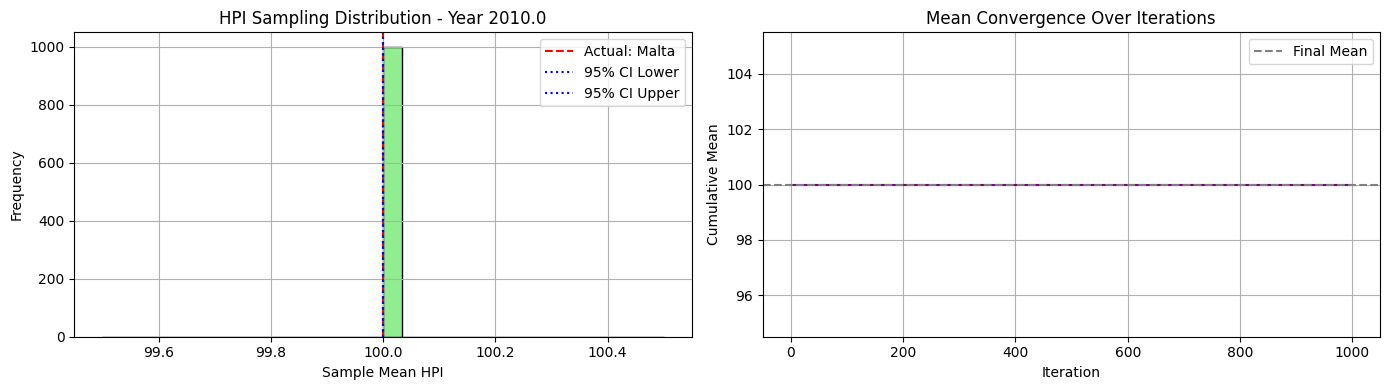

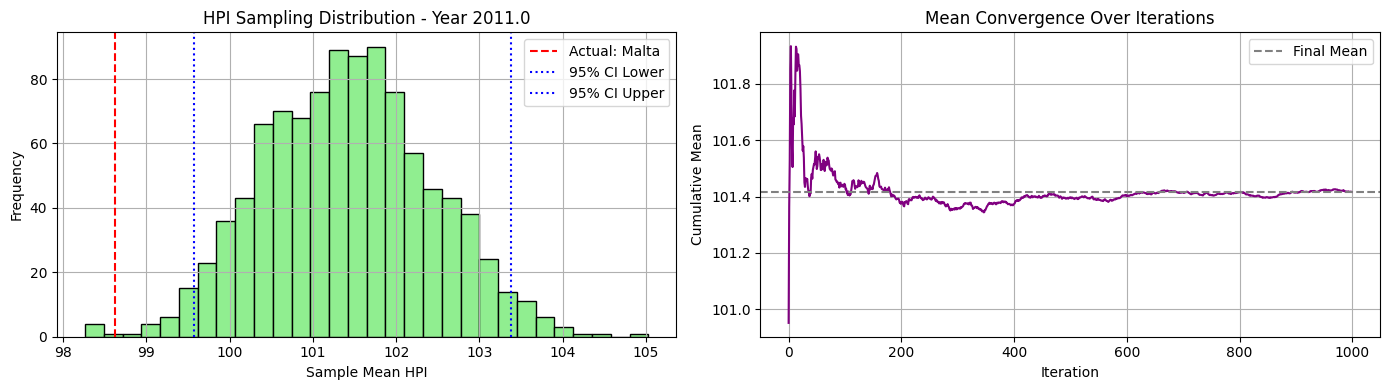

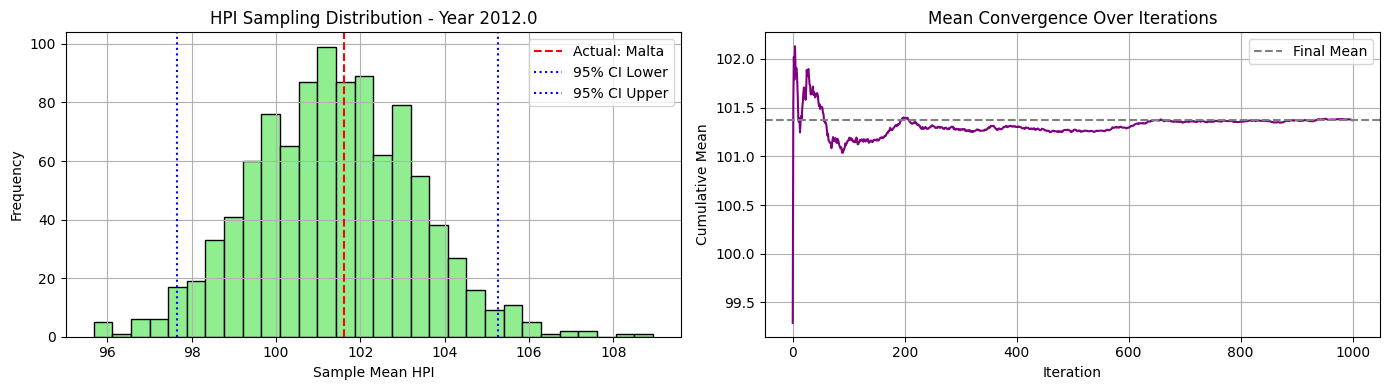

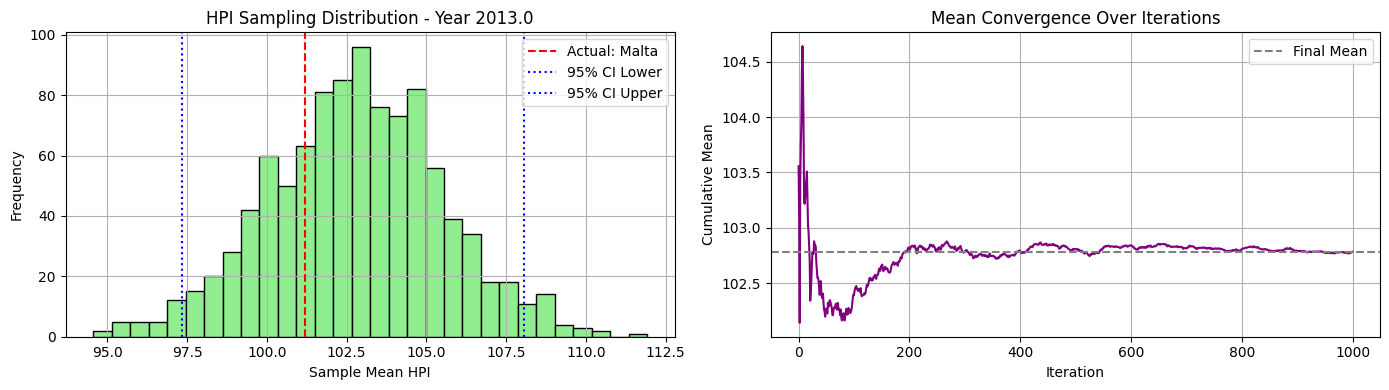

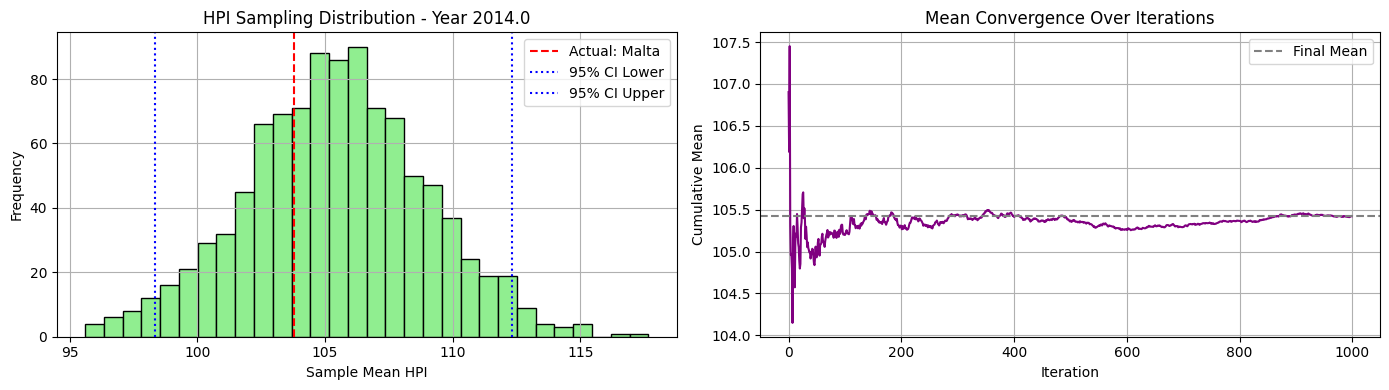

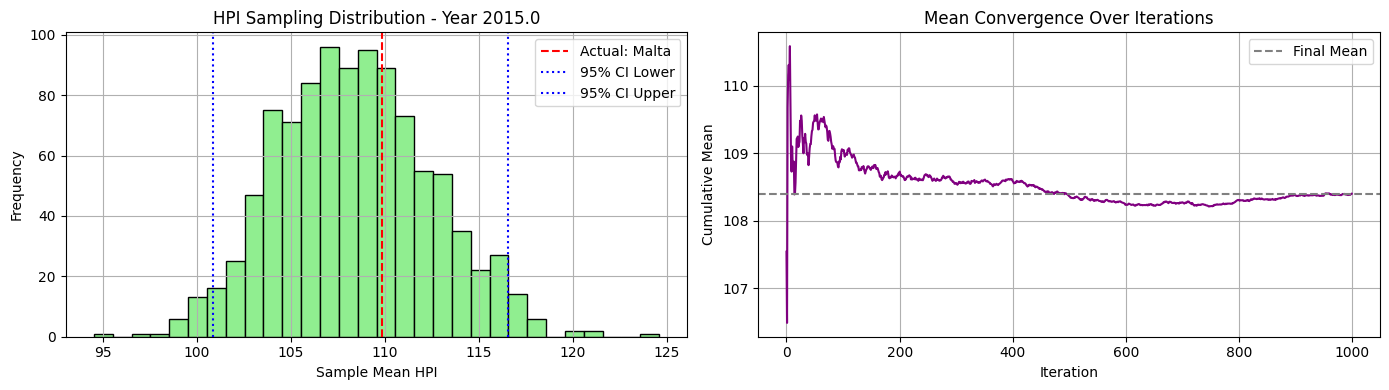

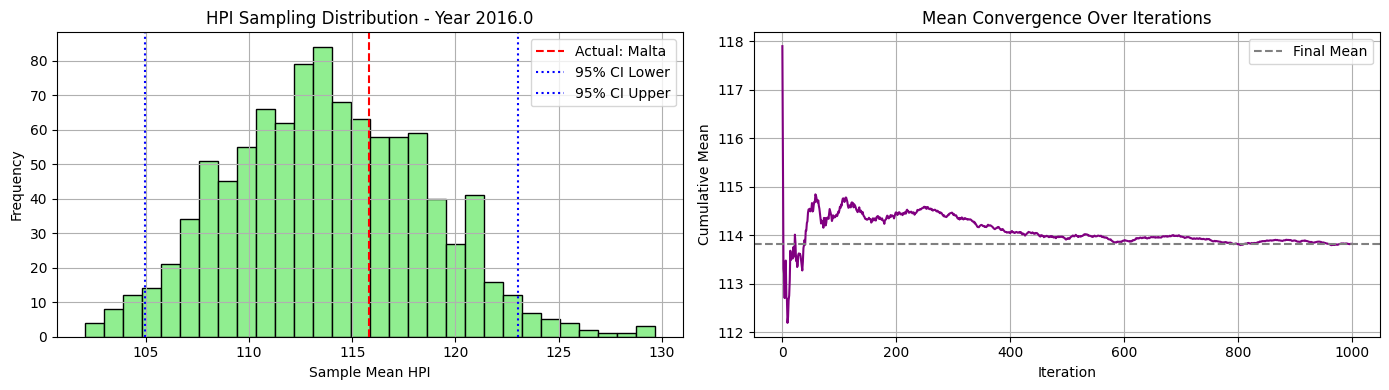

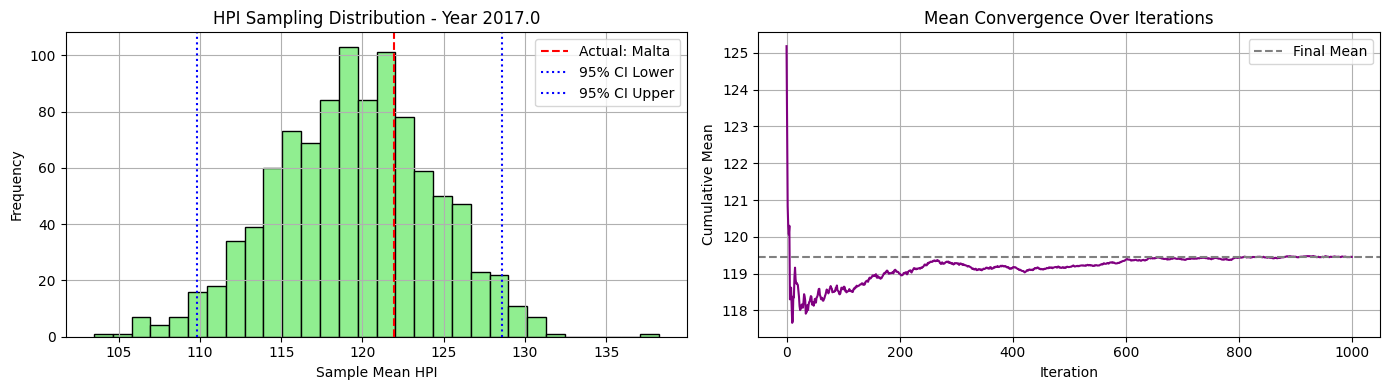

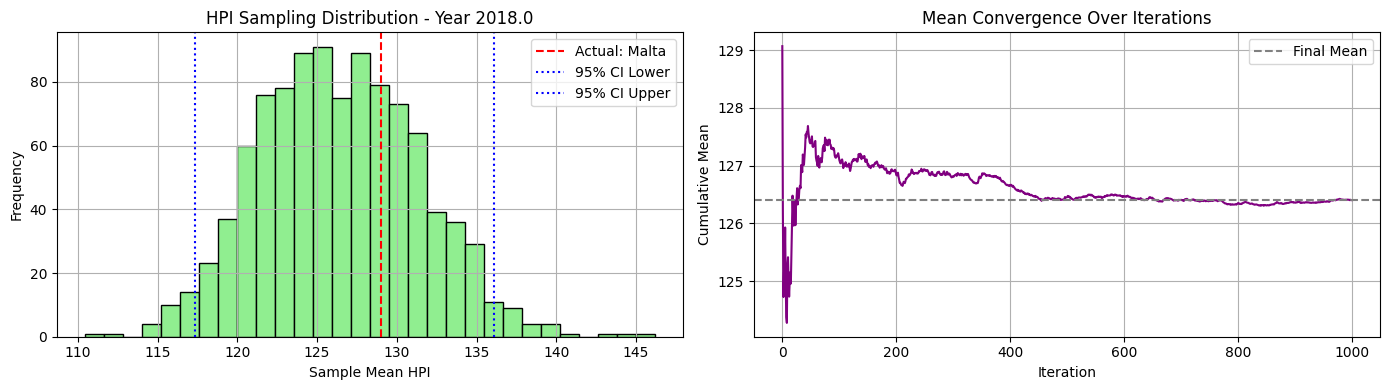

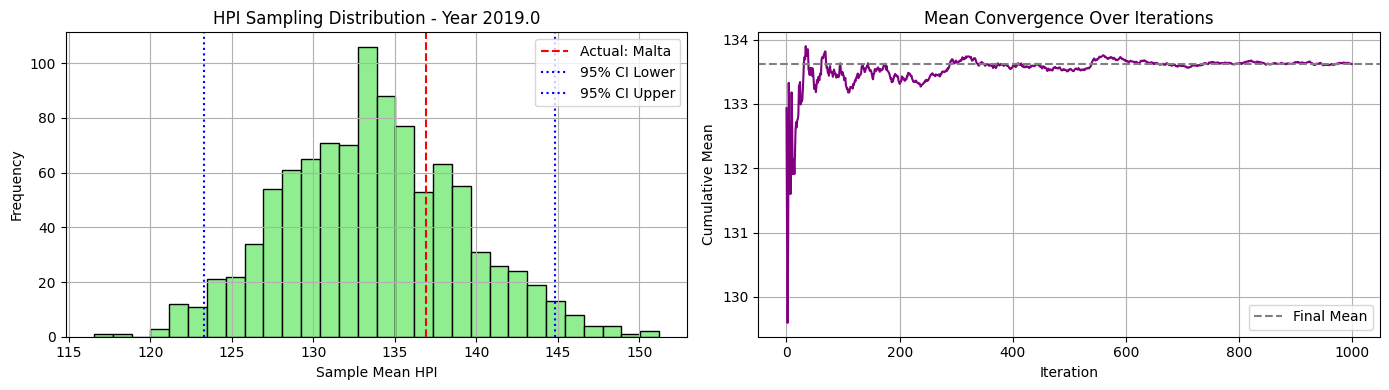

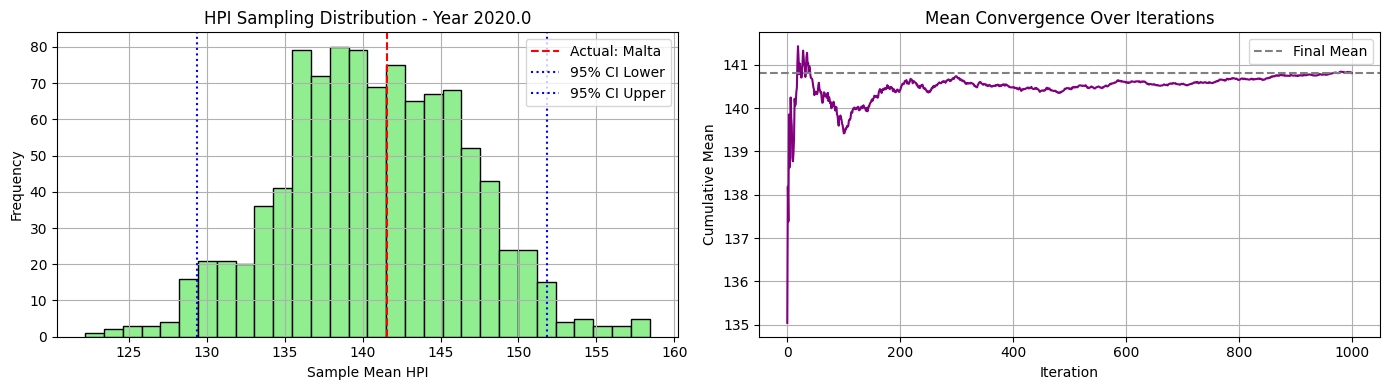

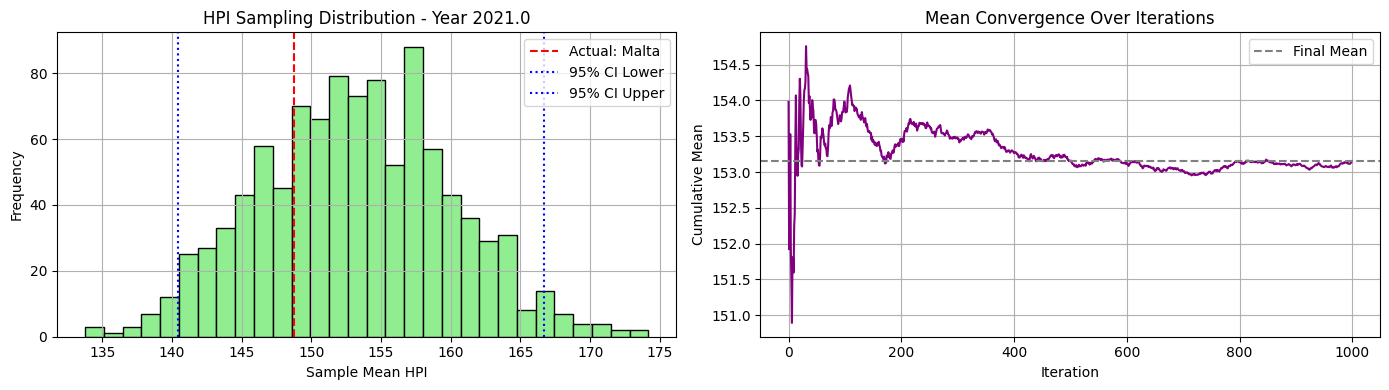

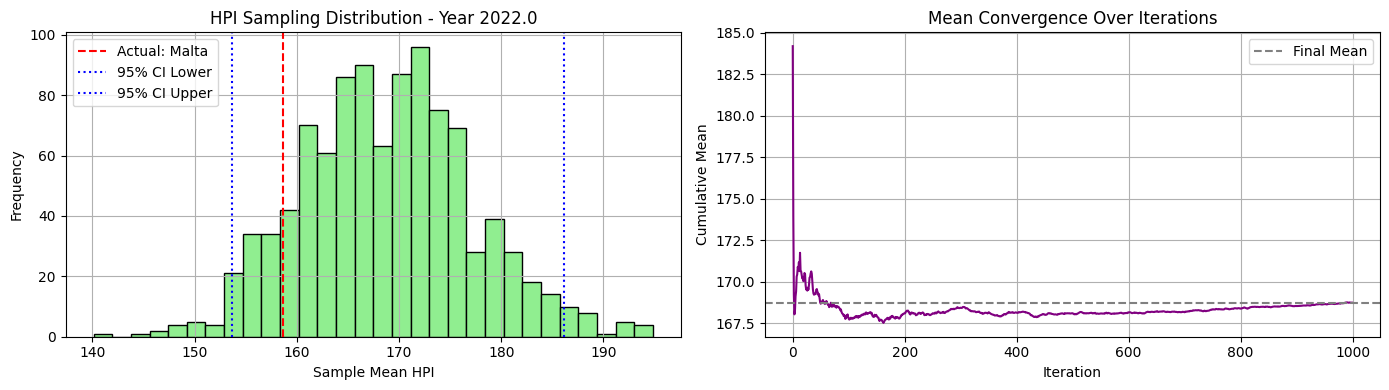

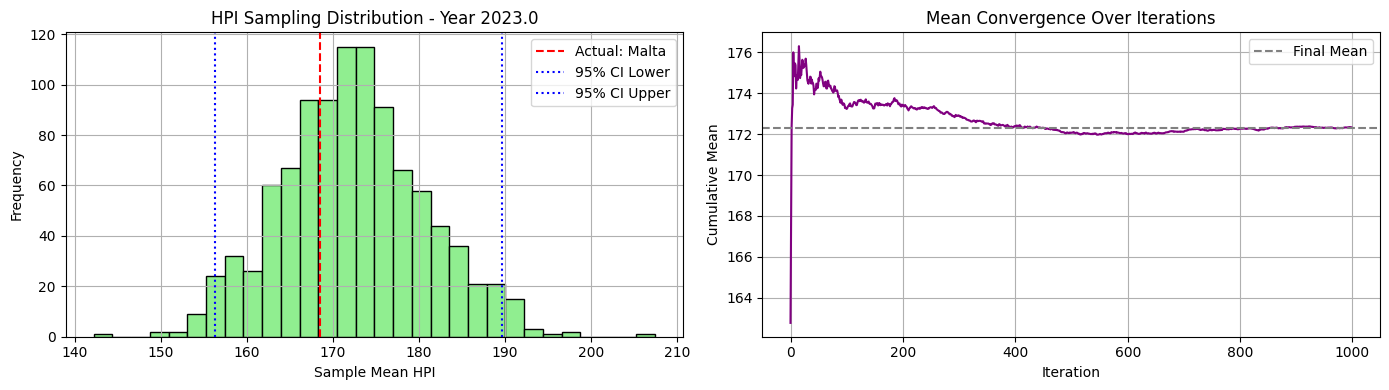

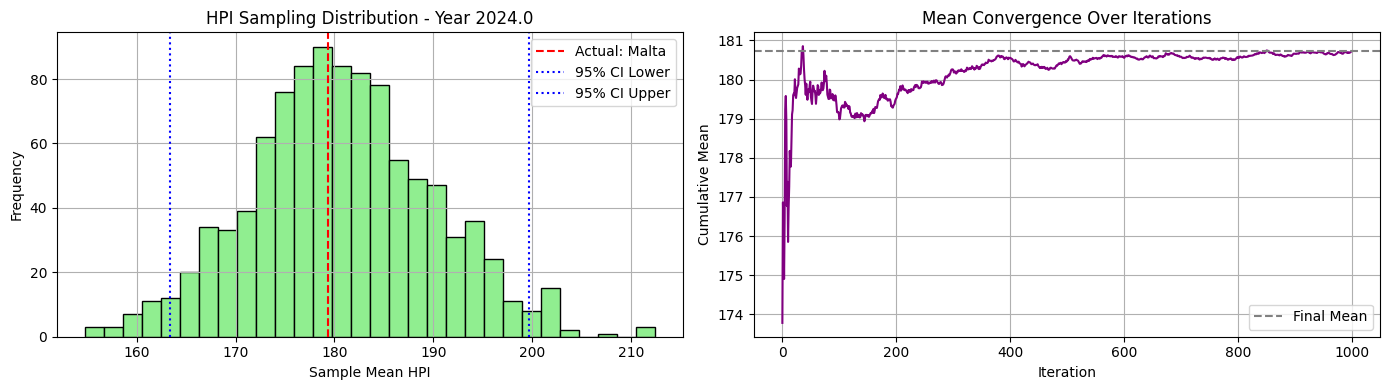

In [63]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, final_pca2, cluster_id=0)

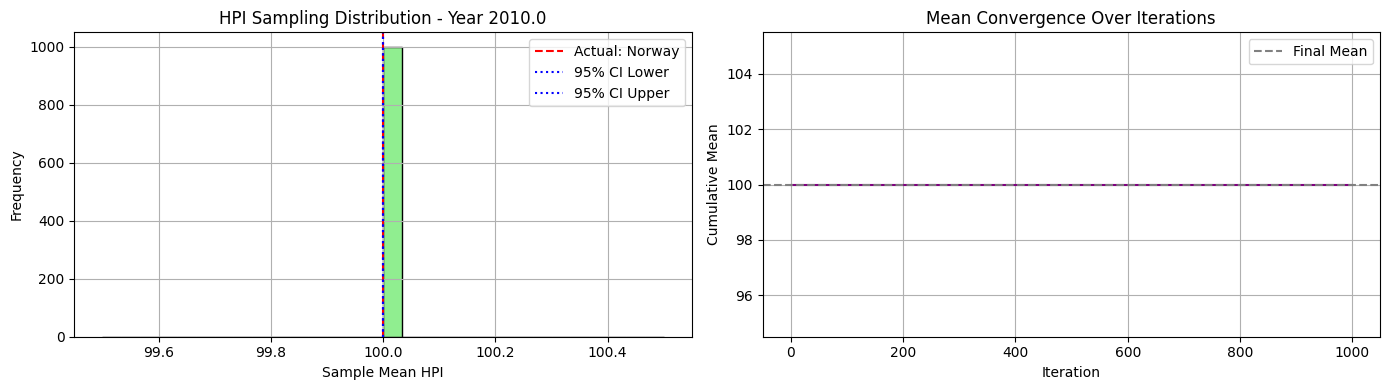

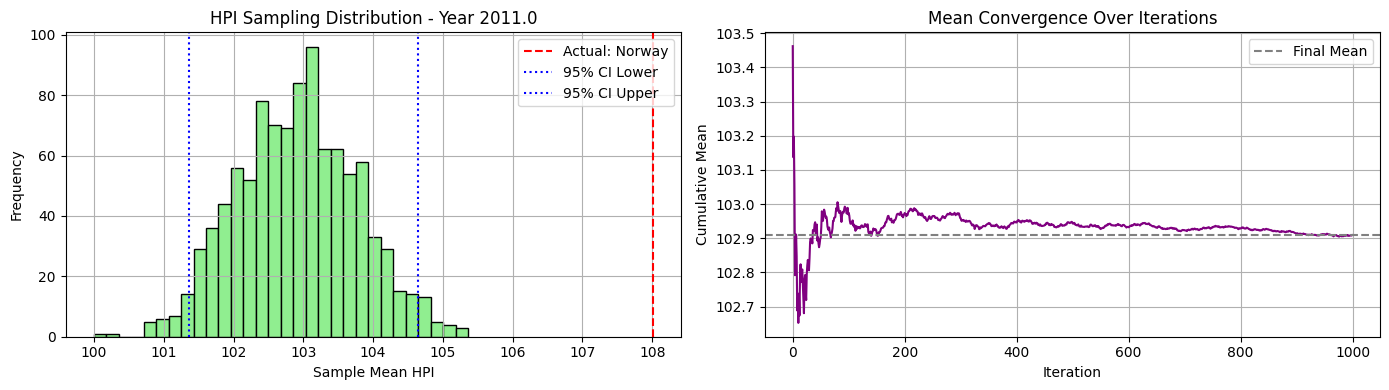

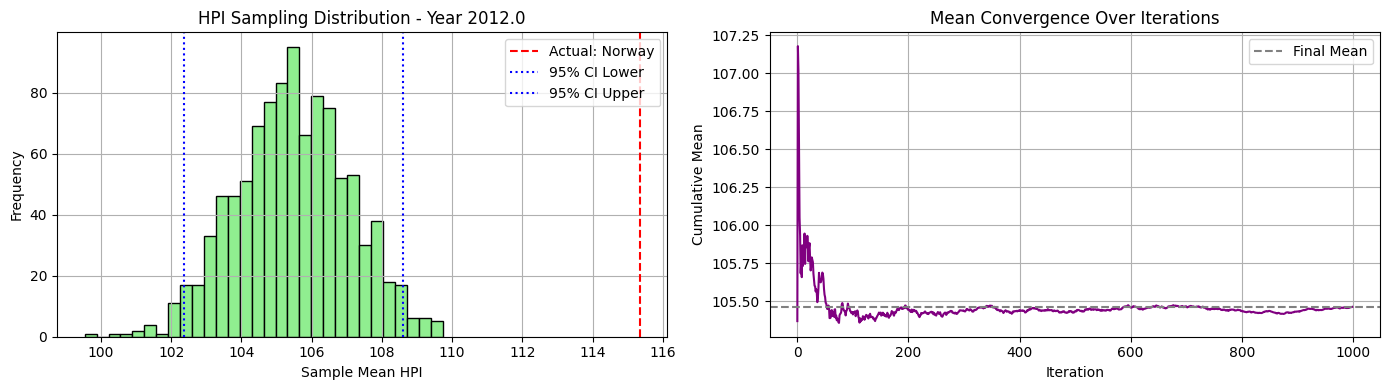

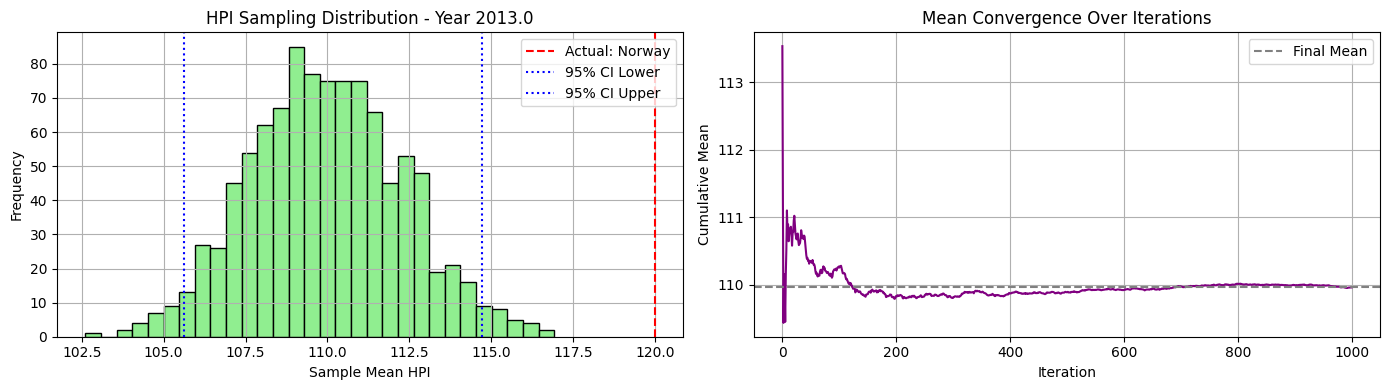

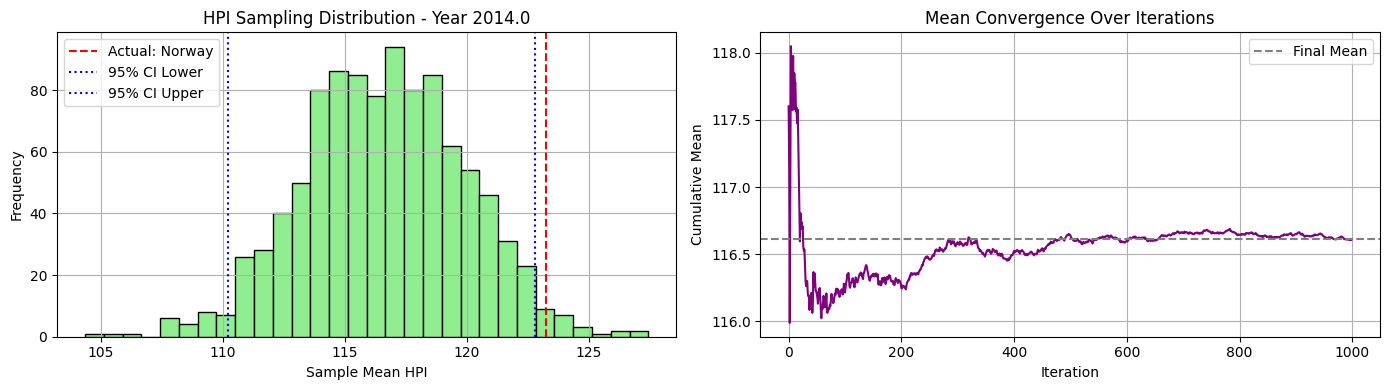

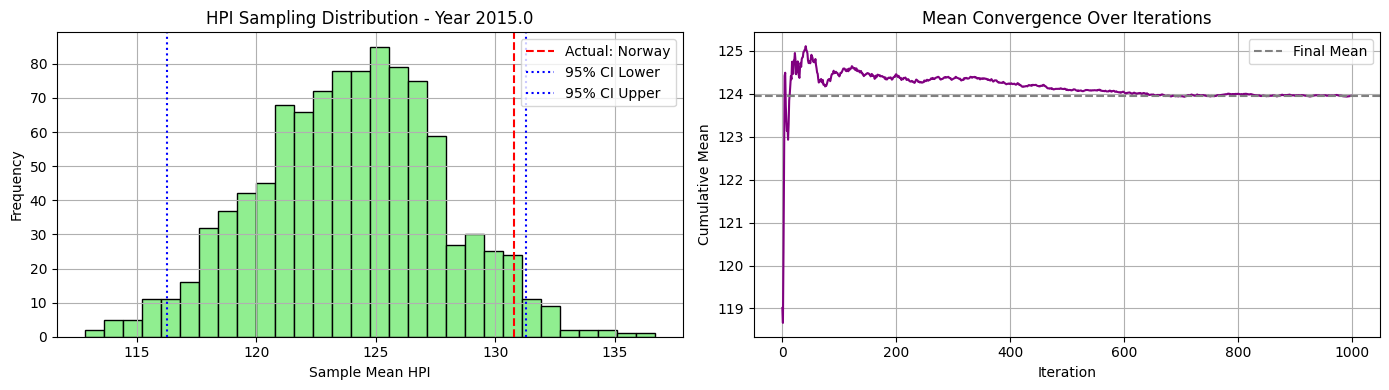

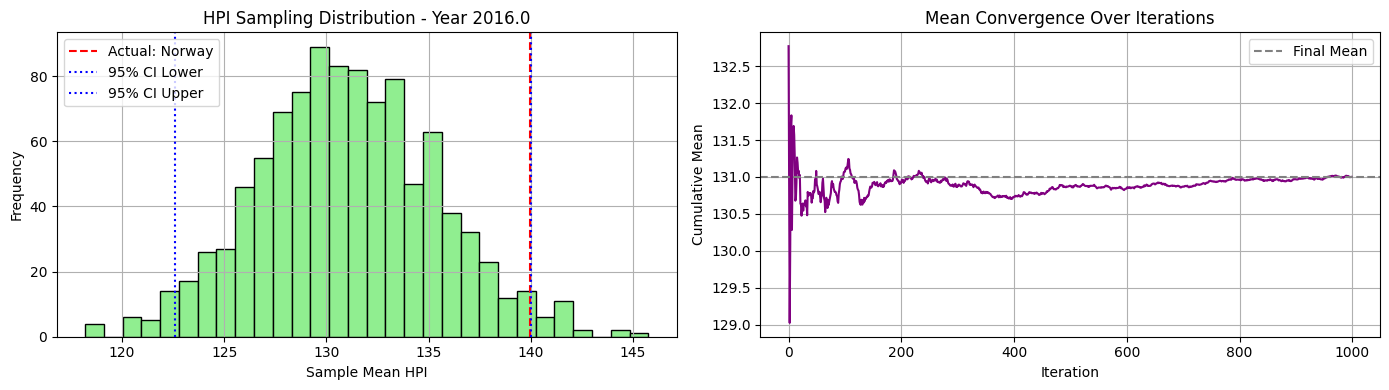

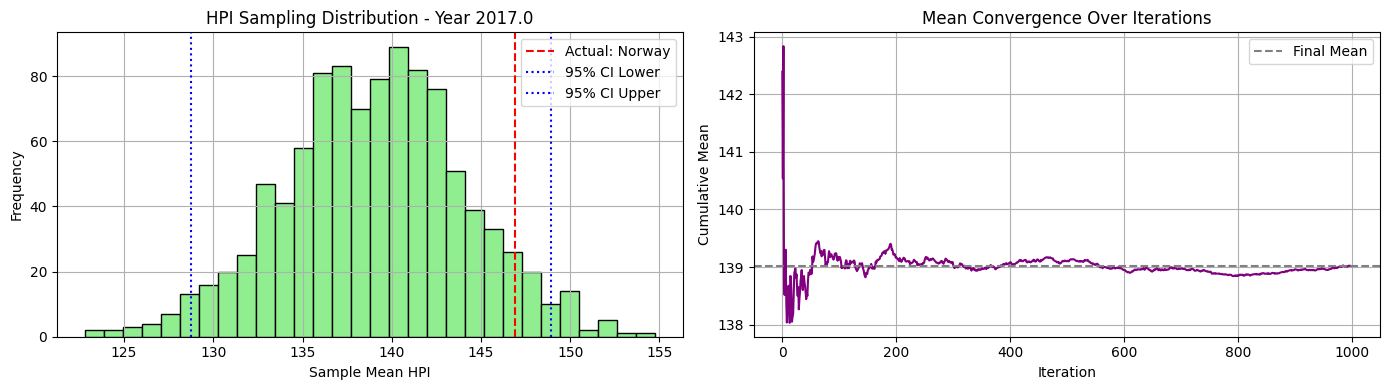

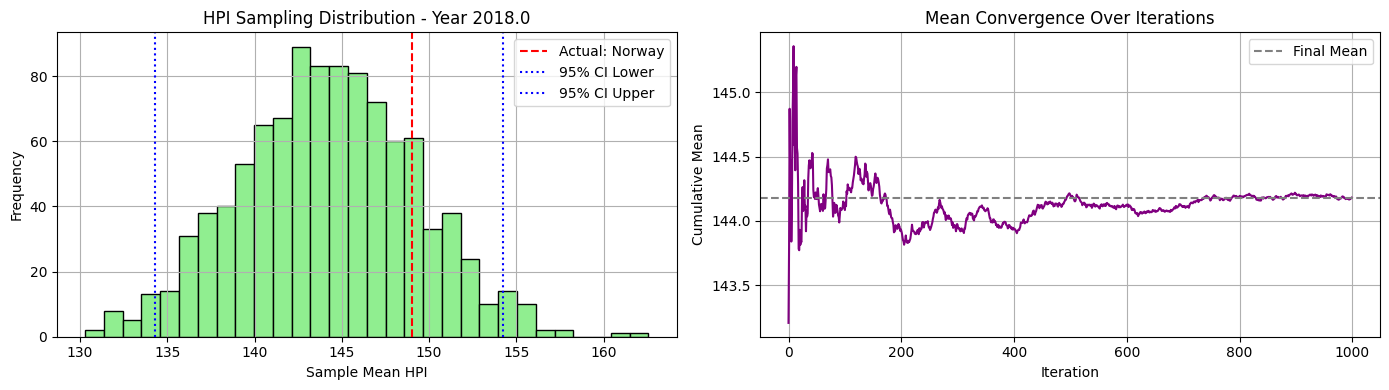

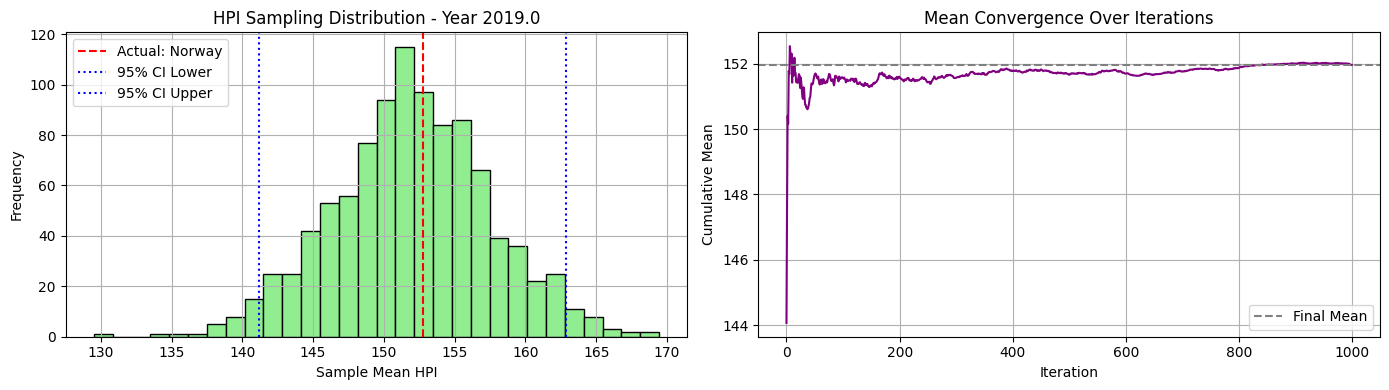

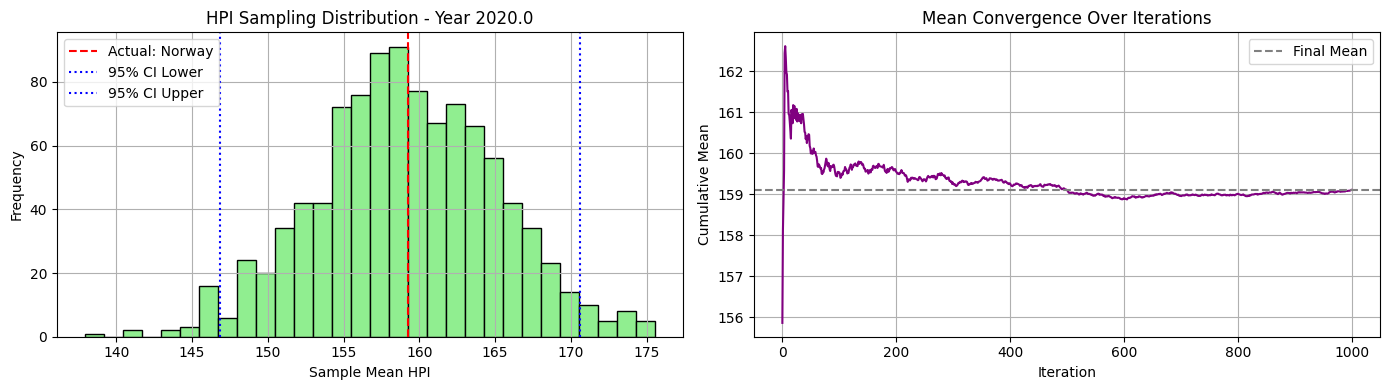

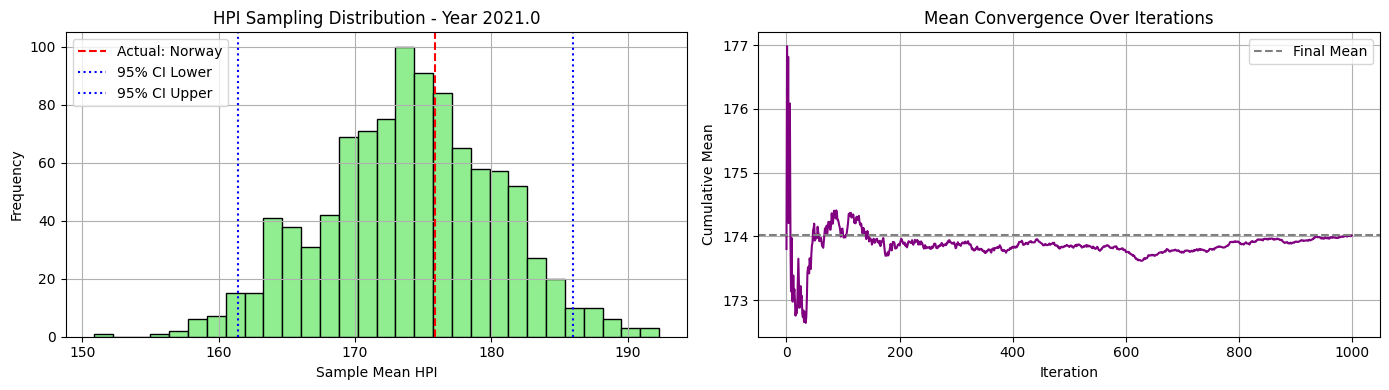

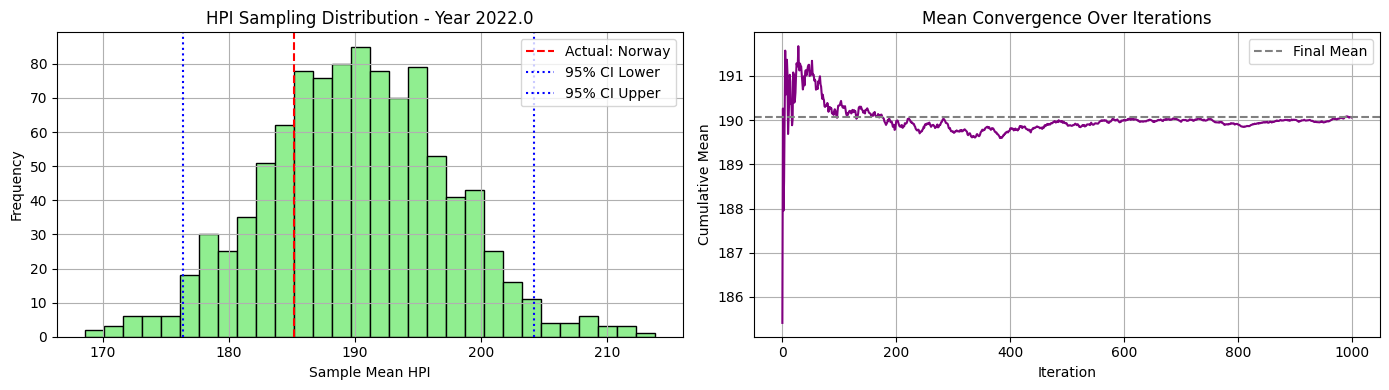

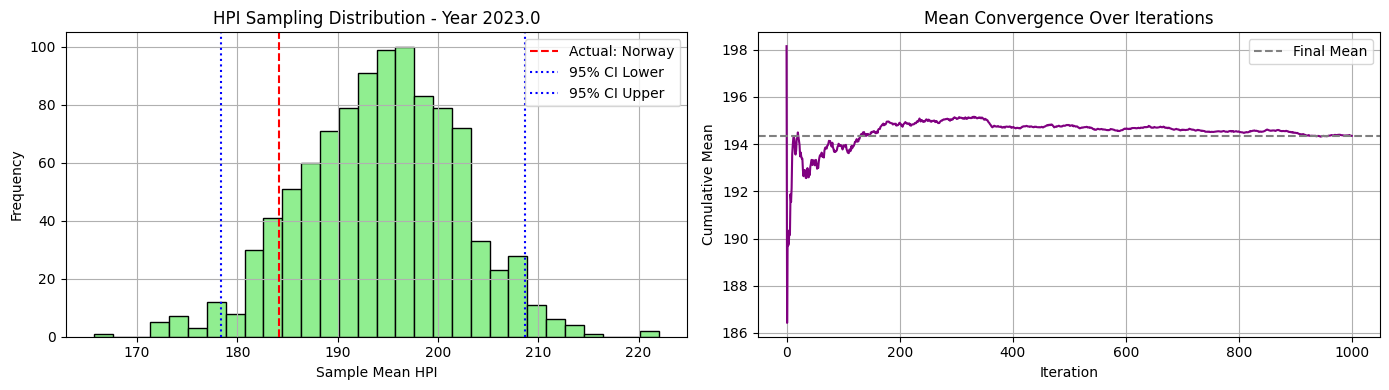

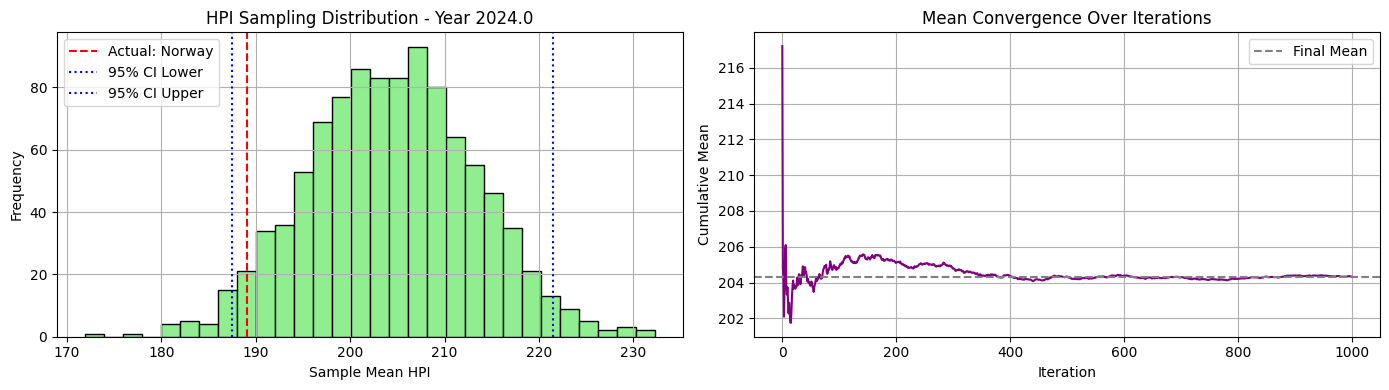

In [64]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, final_pca2, cluster_id=1)

In [65]:
cluster_means_dict = {0:yearly_mean_00, 1:yearly_mean_01}

In [66]:
cluster_means_dict

{0: {np.float64(2010.0): np.float64(100.0),
  np.float64(2011.0): np.float64(101.32782608695652),
  np.float64(2012.0): np.float64(101.39695652173911),
  np.float64(2013.0): np.float64(102.6591304347826),
  np.float64(2014.0): np.float64(105.32347826086956),
  np.float64(2015.0): np.float64(108.5613043478261),
  np.float64(2016.0): np.float64(114.01913043478261),
  np.float64(2017.0): np.float64(119.67826086956521),
  np.float64(2018.0): np.float64(126.55956521739128),
  np.float64(2019.0): np.float64(133.8665217391304),
  np.float64(2020.0): np.float64(141.00260869565219),
  np.float64(2021.0): np.float64(152.90043478260873),
  np.float64(2022.0): np.float64(168.2478260869565),
  np.float64(2023.0): np.float64(172.32782608695652),
  np.float64(2024.0): np.float64(180.46434782608696)},
 1: {np.float64(2010.0): np.float64(100.0),
  np.float64(2011.0): np.float64(103.1662962962963),
  np.float64(2012.0): np.float64(105.82407407407409),
  np.float64(2013.0): np.float64(110.21259259259259)

In [67]:
yearly_mean_py = pd.DataFrame(list(yearly_mean_01.items()), columns=['Año', 'HPI'])

In [68]:
yearly_mean_py

,Año,HPI
0,2010.0,100.000000
1,2011.0,103.166296
2,2012.0,105.824074
3,2013.0,110.212593
4,2014.0,116.847407
5,2015.0,124.001852
6,2016.0,131.159630
7,2017.0,139.437778
8,2018.0,144.597407
9,2019.0,151.626296


In [69]:
yearly_mean_py.to_parquet('../data/synthetic_hpi_paraguay.parquet')

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [70]:
errors2 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01]
}

In [71]:
# Convertir a DataFrame
df_errors2 = pd.DataFrame.from_dict(errors2, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors2 = df_errors2.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors2)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0     933.4285      22.2339
cluster_1     824.7934      21.0405


In [72]:
variances2 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, final_pca2)
for cluster_id, var in variances2.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 892.7050
Cluster 1: Avg HPI Variance = 793.5979


In [73]:
iqr_percent2= percentage_points_within_iqr_by_cluster(df_hpi_winsorized, final_pca2)
print(iqr_percent2)

{np.int32(0): np.float64(51.3), np.int32(1): np.float64(51.6)}


### Plots

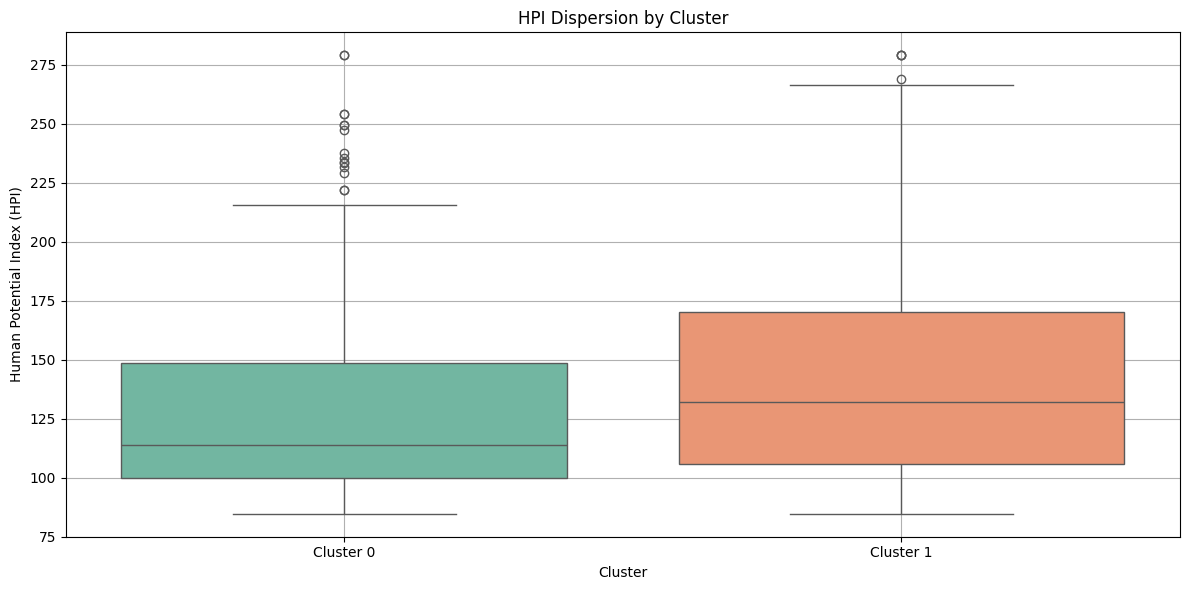

In [74]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, final_pca2)

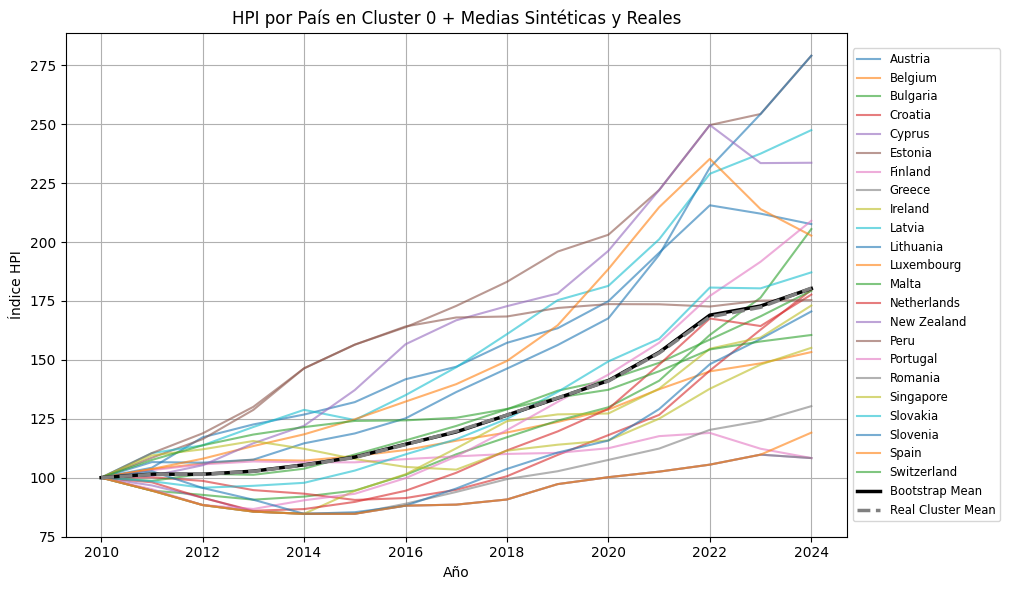

In [75]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, final_pca2, cluster_id=0, yearly_bootstrap_means=yearly_bootstrap_means_00, yearly_mean=yearly_mean_00)

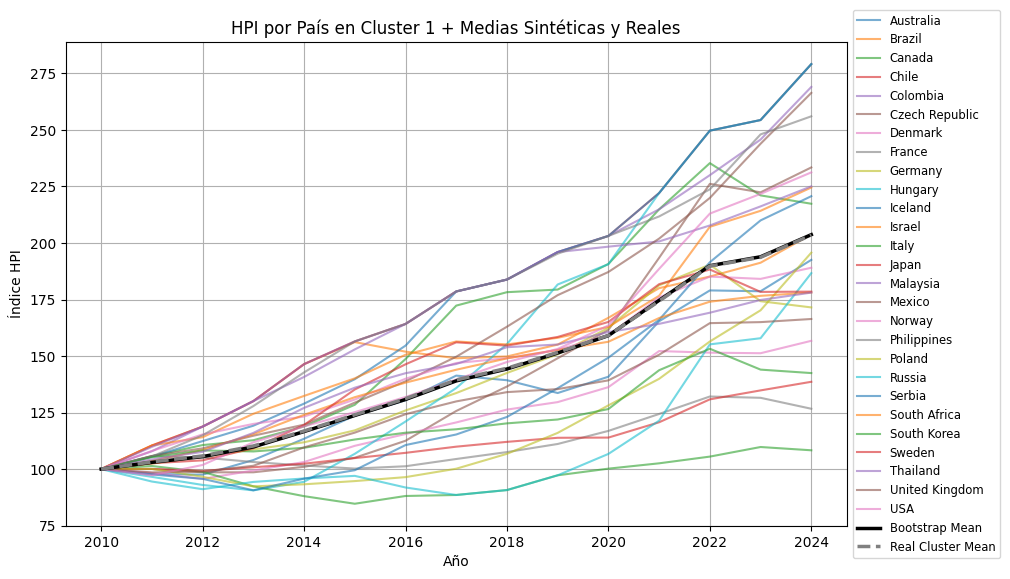

In [76]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, final_pca2, cluster_id=1, yearly_bootstrap_means=yearly_bootstrap_means_01, yearly_mean=yearly_mean_01)

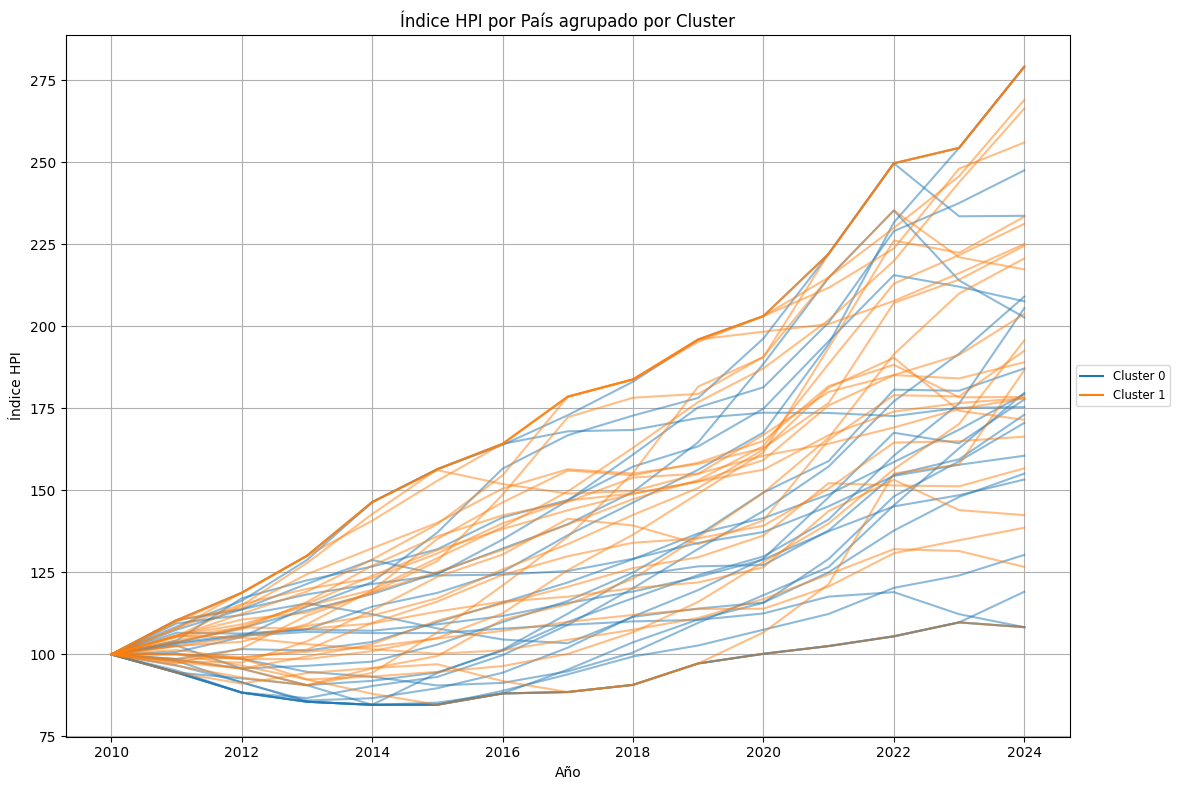

In [77]:
plot_all_clusters_hpi(df_hpi_winsorized, final_pca2)

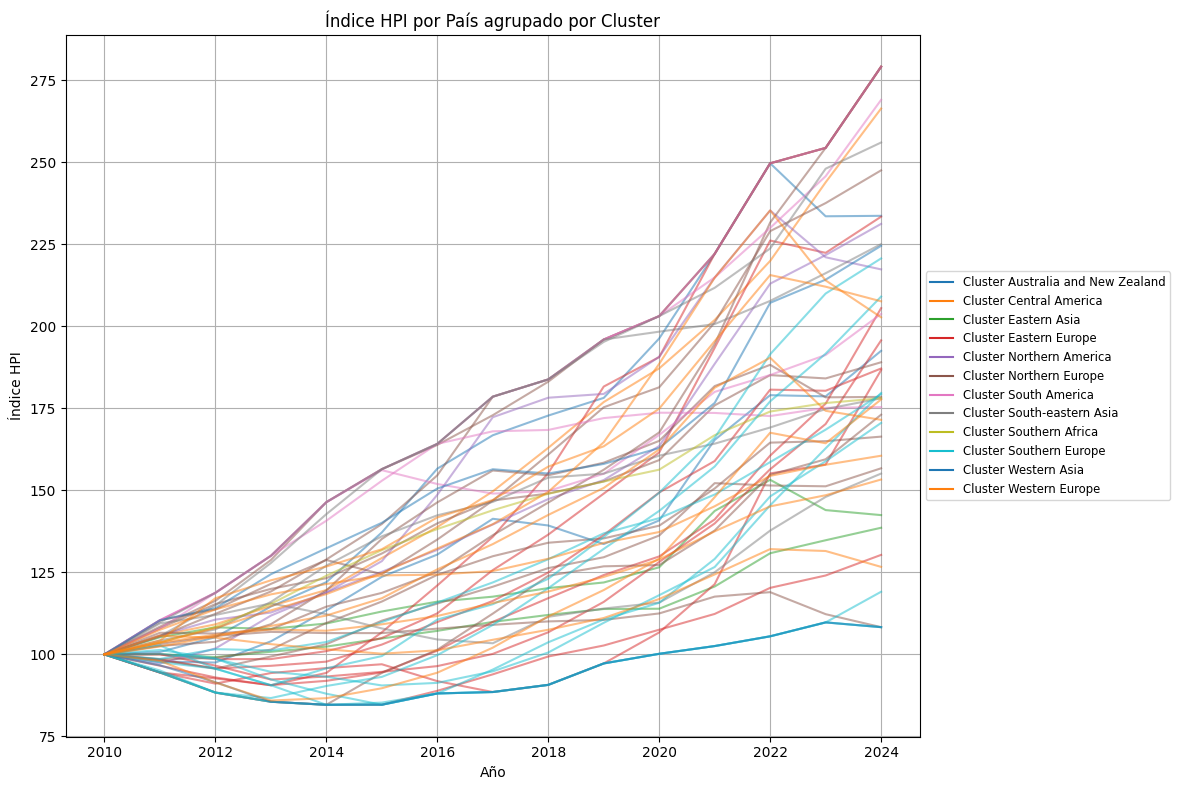

In [78]:
plot_all_clusters_hpi(df_hpi_winsorized, final_pca2, cluster_column='UNregion')

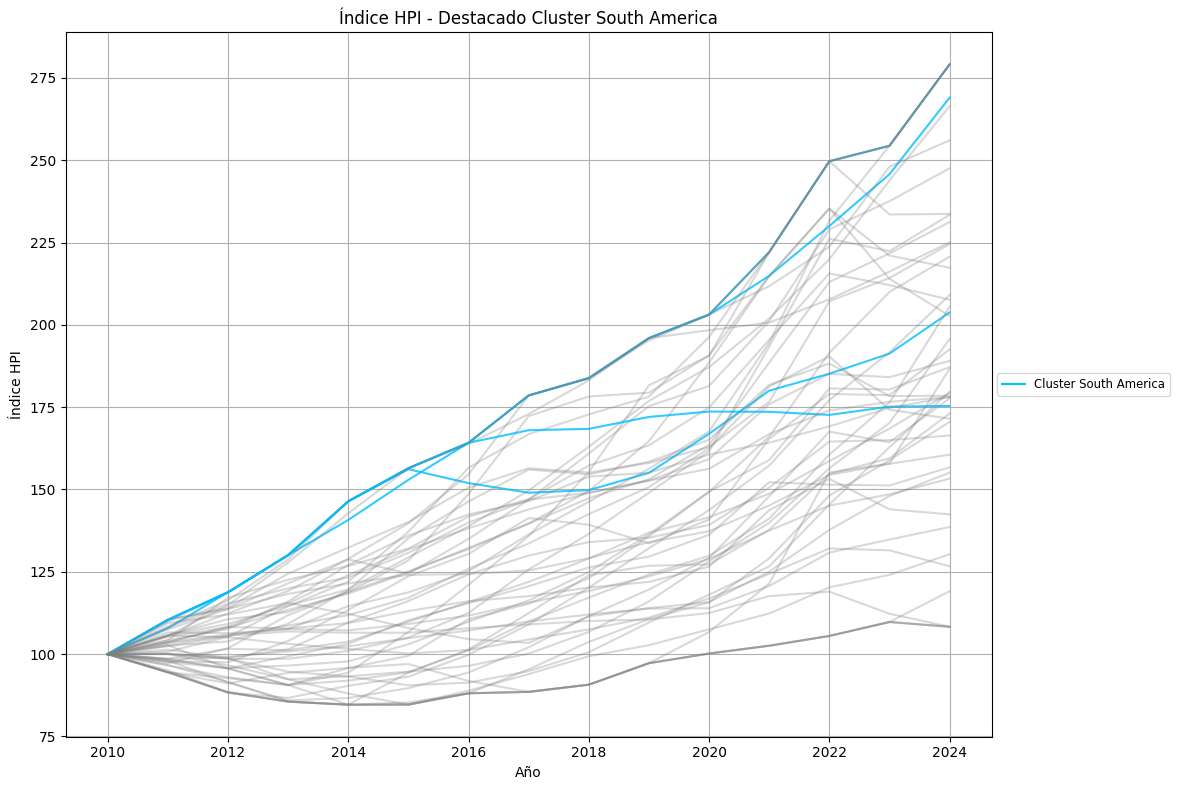

In [79]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='South America')

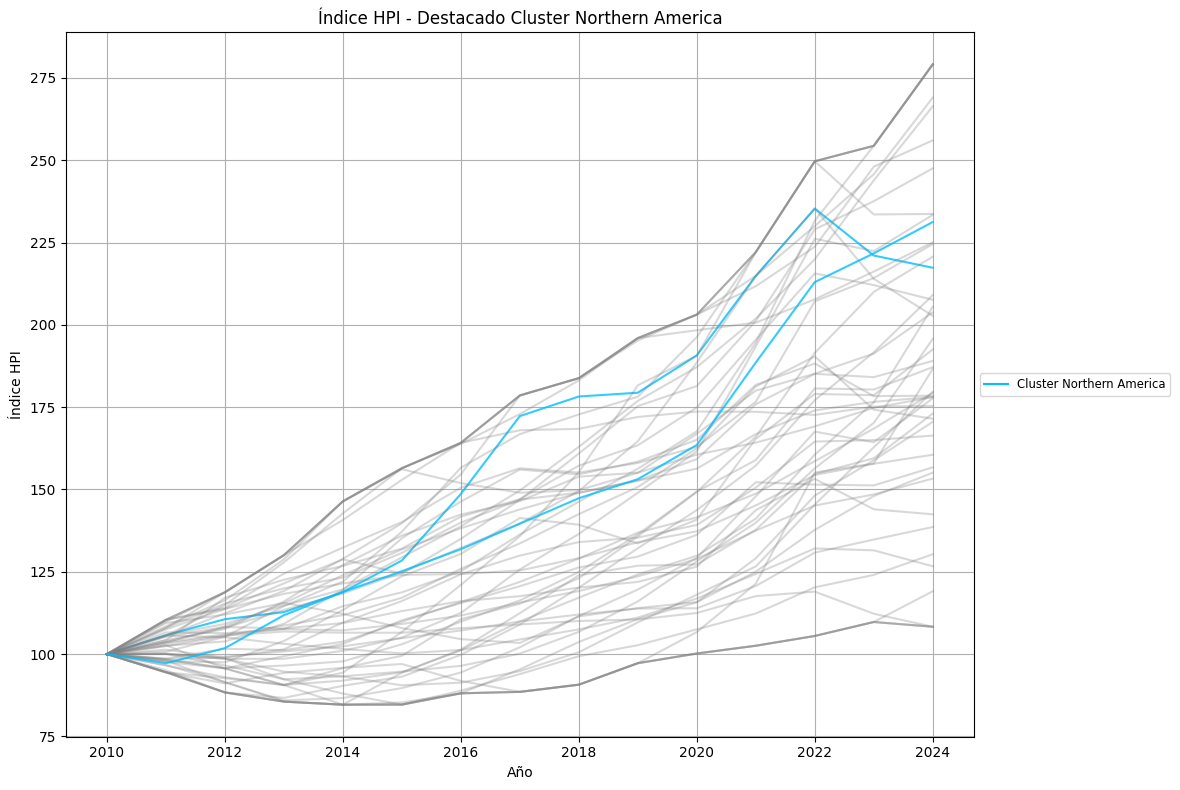

In [80]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='Northern America')

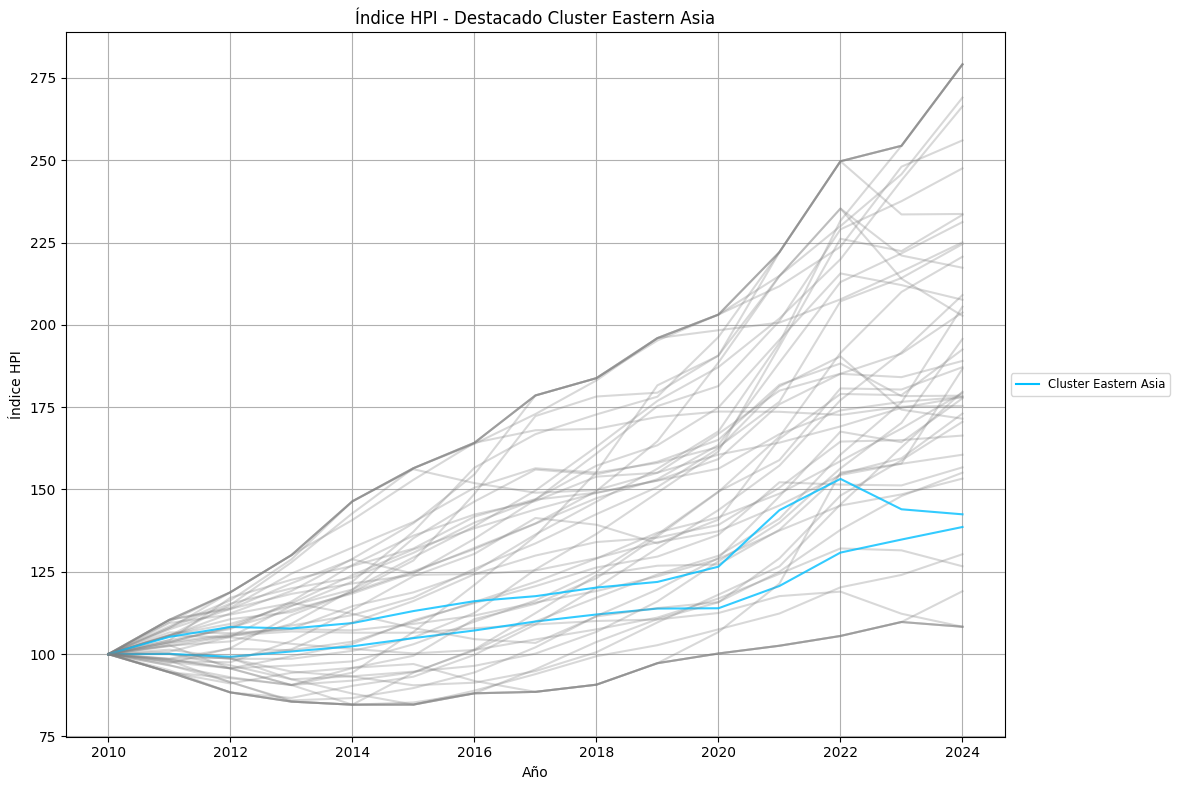

In [81]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='Eastern Asia')

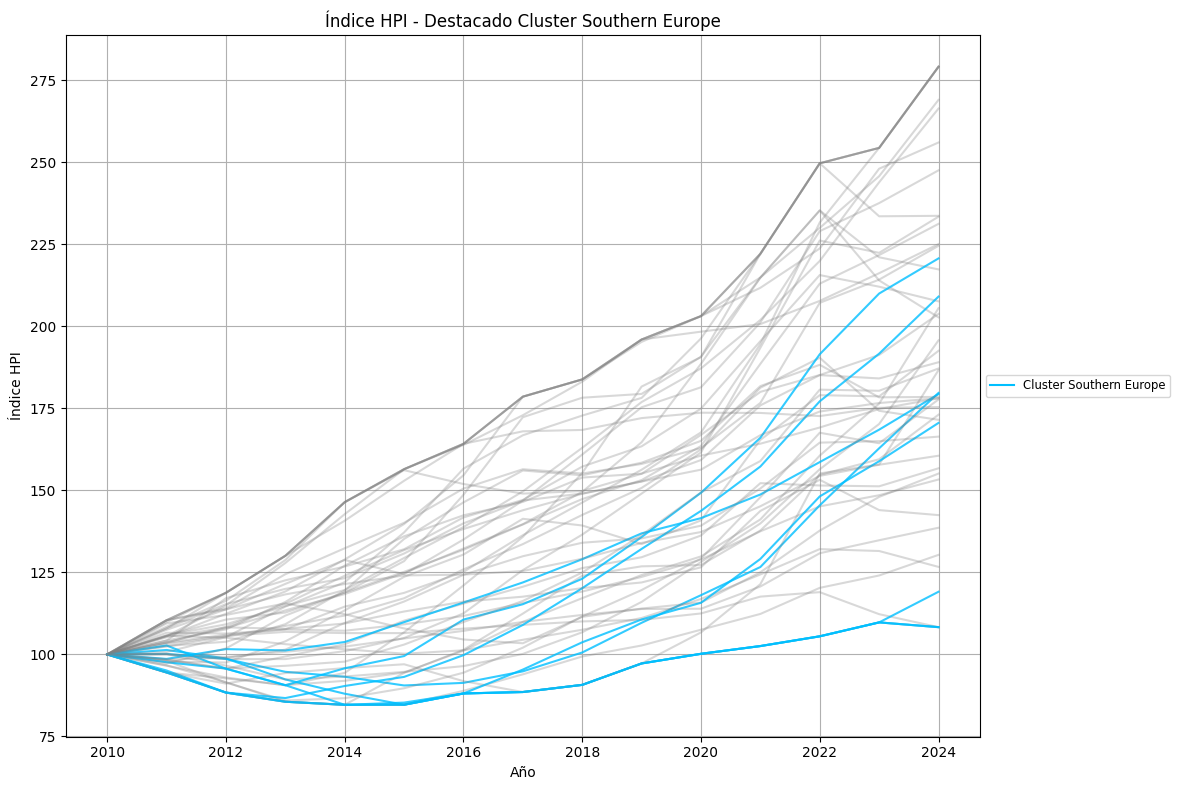

In [82]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='Southern Europe')

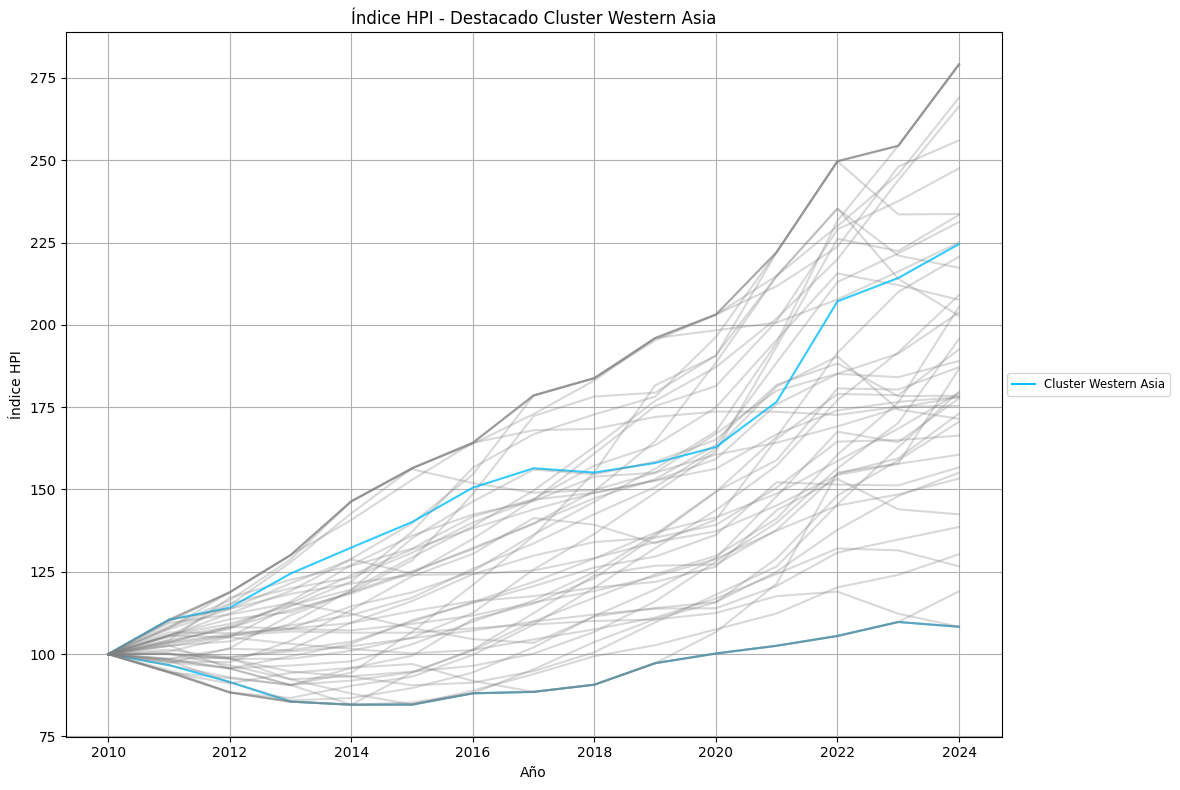

In [83]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='Western Asia')

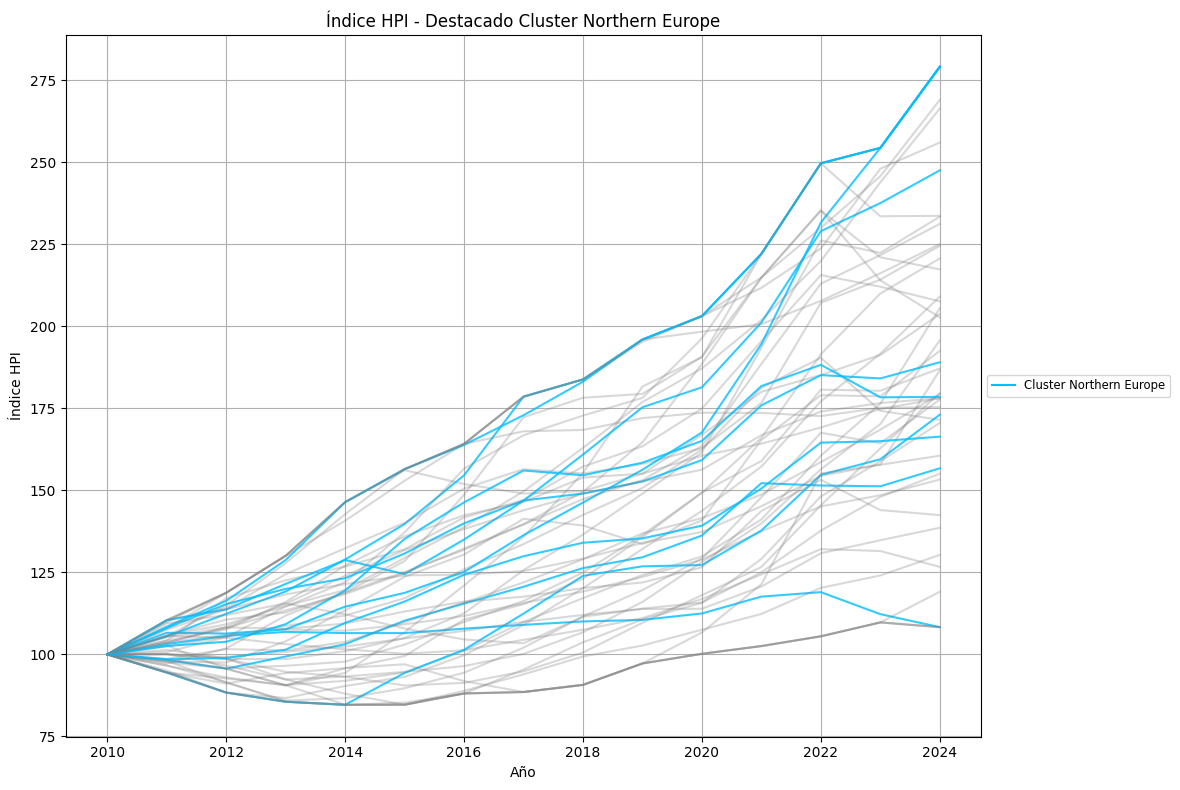

In [84]:
plot_selected_cluster_highlight(df_hpi_winsorized, final_pca2, cluster_column='UNregion', selected_cluster='Northern Europe')

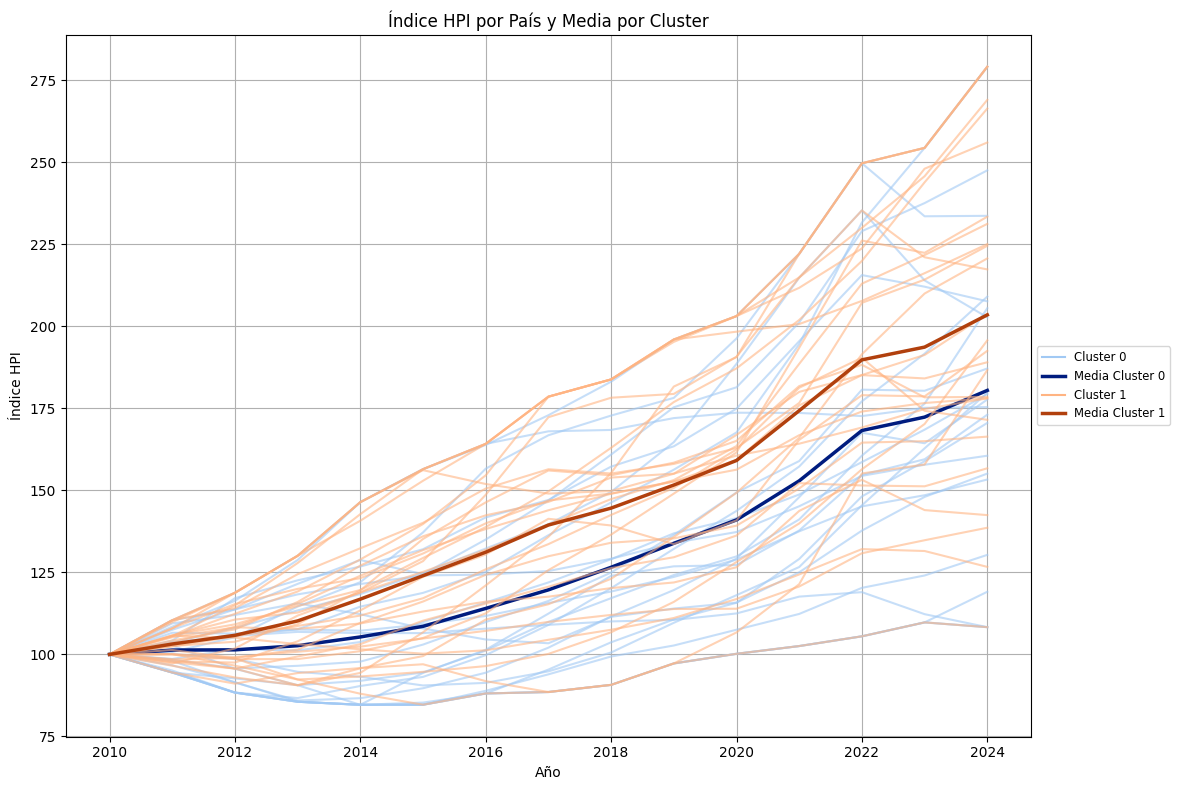

In [85]:
plot_clusters_with_external_means(df_hpi_winsorized, final_pca2, cluster_means_dict=cluster_means_dict)

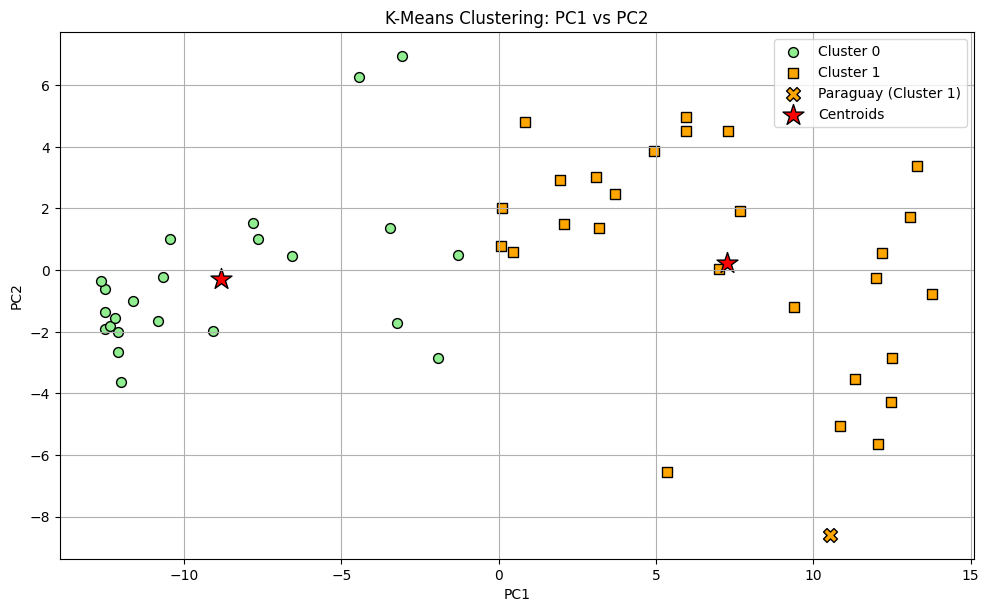

In [86]:
plot_kmeans_clusters(final_pca2,'PC1', 'PC2', km_c2_ni20_maxi500_pca2)

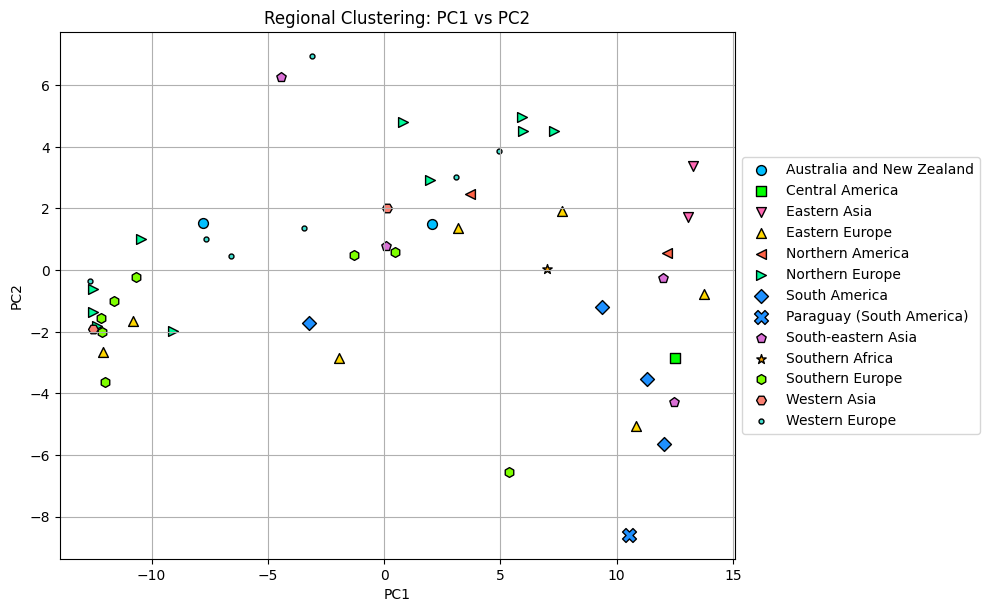

In [87]:
plot_region_clusters(final_pca2, 'PC1', 'PC2')

In [88]:
final_pca2.head()

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
0,2.064226,1.489614,1,Australia,AUS,Oceania,Australia and New Zealand
1,-7.648769,0.995875,0,Austria,AUT,Europe,Western Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe,Western Europe
3,9.370254,-1.189187,1,Brazil,BRA,America,South America
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe,Eastern Europe


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [60]:
pd.set_option('display.max_columns', None)

In [61]:
log_df = pd.read_parquet('../data/log_performance/new_log_performance.parquet')

In [62]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,NaN,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,NaN,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
2,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,NaN,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,NaN,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,NaN,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,NaN,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,NaN,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,NaN,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN
8,kmeans_++_2c_h2_2delete_countries_exclude,2025-09-18 17:00,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420313,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'live

In [74]:
new_entry3 = {
    'experiment_name': 'kmeans_++_2c_h2_2delete_pca_countries_exclude',
    'experiment_date': '2025-09-20 22:43',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 51,
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score_pca2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'outliers_handling_clustering': 'Winsorization x6',
    'used_all_variables_for_clustering': "['gdp', 'inflation', 'agr_land', 'livestock_prod']",
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x4, rounding',
    'outliers_handling_sampling': 'Winsorization x4',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 51,
    'mse_score': df_errors2['Average MSE'].mean(),
    'mae_score': df_errors2['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_29',
    'pca_ratio_sum': sum_var_expl_sum,
    'pca_ratio_values': tuple_var_expl_pca,
    'Variance_Cluster_0': round(float(variances2[0]),2),
    'Variance_Cluster_1': round(float(variances2[1]),2),
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_percent2[0]),
    'IQR_Count_Cluster_1':int(iqr_percent2[1]),
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [77]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_13664\1527126143.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)


In [78]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,NaN,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,NaN,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,NaN,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN
8,kmeans_++_2c_h2_2delete_countries_exclude,2025-09-18 17:00,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420313,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Delete Countries x2, Winsorization x4, rounding",Winsorization x4,bootstrap,None,51.0,874.340400,21.932350,hypothesis_test_026,NaN,None,955.31,722.29,NaN,NaN,49.0,53.0,NaN,NaN
9,kmeans_++_2c_h2_2delete_pca_countries_exclude,2025-09-20 22:43,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.563596,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x4, rounding",Winsorization x4,bootstrap,None,51.0,877.778200,21.621850,hypothesis_test_29,0.74,"(0.66, 0.08)",892.71,793.60,NaN,NaN,51.0,51.0,NaN,NaN


In [79]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [80]:
log_df.to_parquet('../data/log_performance/new_log_performance.parquet')

### Plot Clusters

In [81]:
def plot_kmeans_clusters(df, x_col, y_col, model, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    y_km = df[cluster_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por cluster
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    # Graficar cada cluster
    for i in range(model.n_clusters):
        cluster_mask = (y_km == i)
        cluster_color = colors[i]
        cluster_marker = markers[i]

        # Separar Paraguay del resto
        paraguay_mask = cluster_mask & (countries == highlight_country)
        others_mask = cluster_mask & (countries != highlight_country)

        # Graficar otros países del cluster
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=cluster_color, marker=cluster_marker,
                    edgecolor='black', label=f'Cluster {i}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=cluster_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} (Cluster {i})')

    # Graficar centroides
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                s=250, marker='*', c='red', edgecolor='black', label='Centroids')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'K-Means Clustering: {x_col} vs {y_col}')
    plt.show()

In [82]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [83]:
final_pca2.head()

,PC1,PC2,cluster,Country,ISO_A3,Continent
0,2.064226,1.489614,1,Australia,AUS,Oceania
1,-7.648769,0.995875,0,Austria,AUT,Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe
3,9.370254,-1.189187,1,Brazil,BRA,America
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe


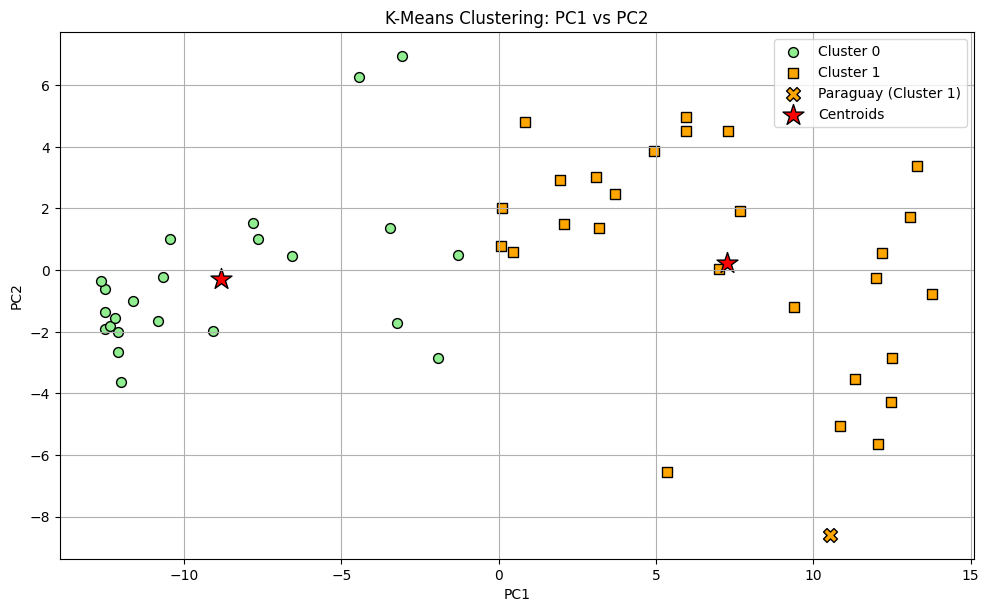

In [84]:
plot_kmeans_clusters(final_pca2, 'PC1', 'PC2', km_c2_ni20_maxi500_pca2)

### With 3 clusters

In [85]:
km_c3_ni20_maxi500_pca2 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [86]:
ym_c3_ni20_maxi500_pca2 = km_c3_ni20_maxi500_pca2.fit(pca_df)

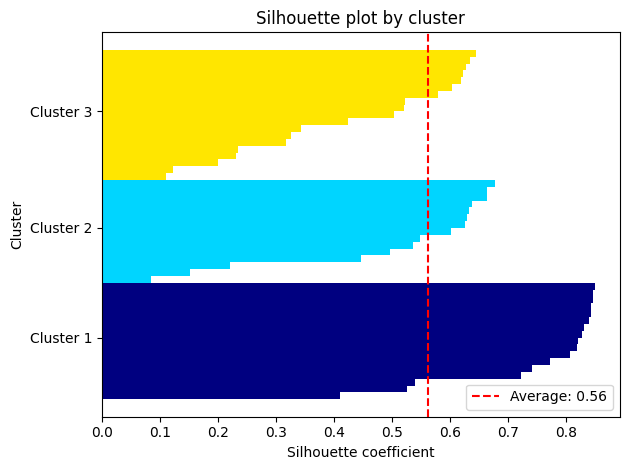

In [87]:
silhoutte_score_c3_pca2 = plot_silhouette(ym_c3_ni20_maxi500_pca2, pca_df)

In [88]:
final_pca2_c3 = pca_df.copy()
final_pca2_c3['cluster'] = ym_c3_ni20_maxi500_pca2.labels_
final_pca2_c3.head()

,PC1,PC2,cluster
0,2.064226,1.489614,2
1,-7.648769,0.995875,0
2,-6.580014,0.441960,0
3,9.370254,-1.189187,1
4,-10.818940,-1.642285,0


In [89]:
final_pca2_c3['Country'] = one_point_countries_win6.Country

In [90]:
final_pca2_c3['ISO_A3'] = coco.convert(names=final_pca2_c3['Country'], to='ISO3')
final_pca2_c3.loc[:, 'Continent'] = coco.convert(
    names=final_pca2_c3['Country'], to='continent'
)

In [91]:
final_pca2_c3.head()

,PC1,PC2,cluster,Country,ISO_A3,Continent
0,2.064226,1.489614,2,Australia,AUS,Oceania
1,-7.648769,0.995875,0,Austria,AUT,Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe
3,9.370254,-1.189187,1,Brazil,BRA,America
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe


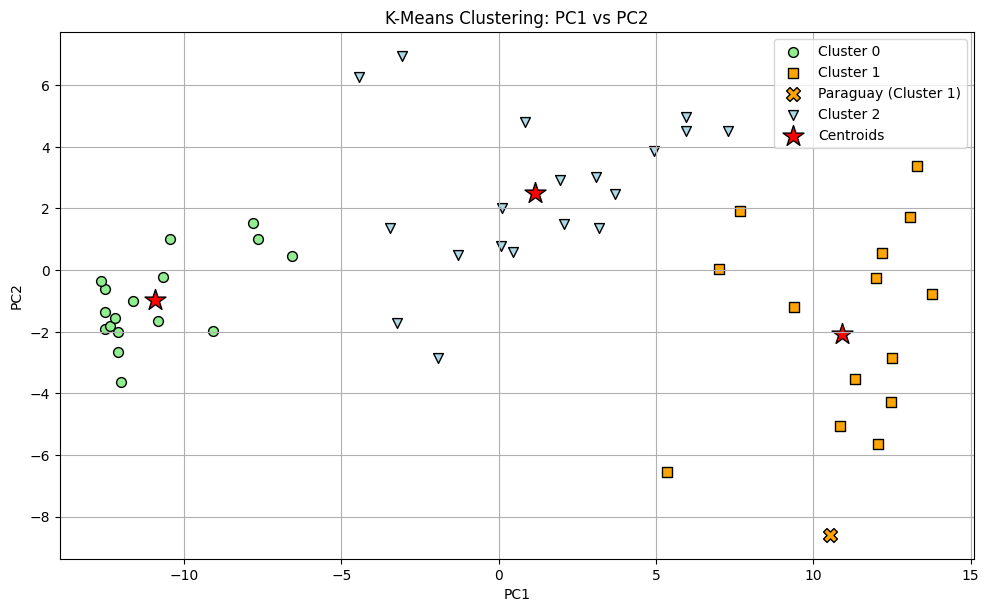

In [92]:
plot_kmeans_clusters(final_pca2_c3, 'PC1', 'PC2', km_c3_ni20_maxi500_pca2)

### Sampling Experiment

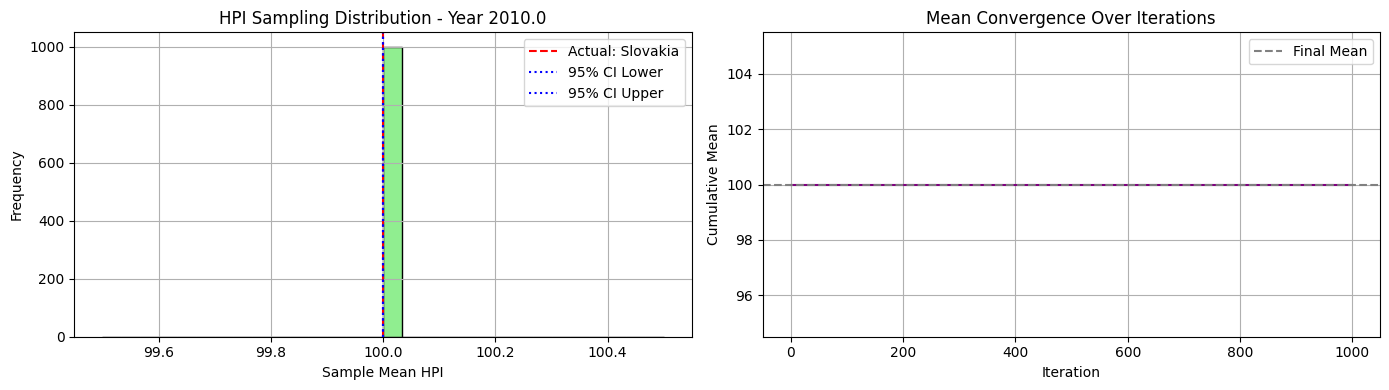

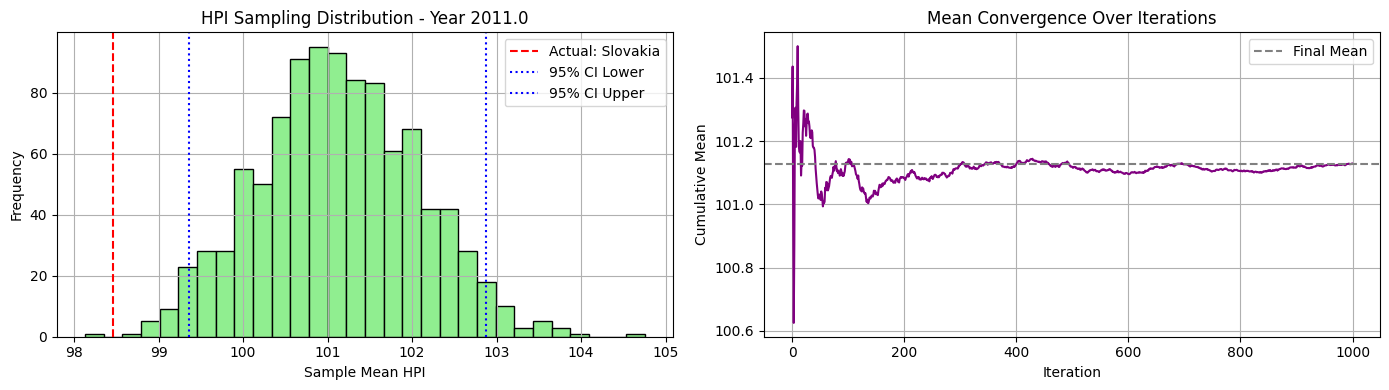

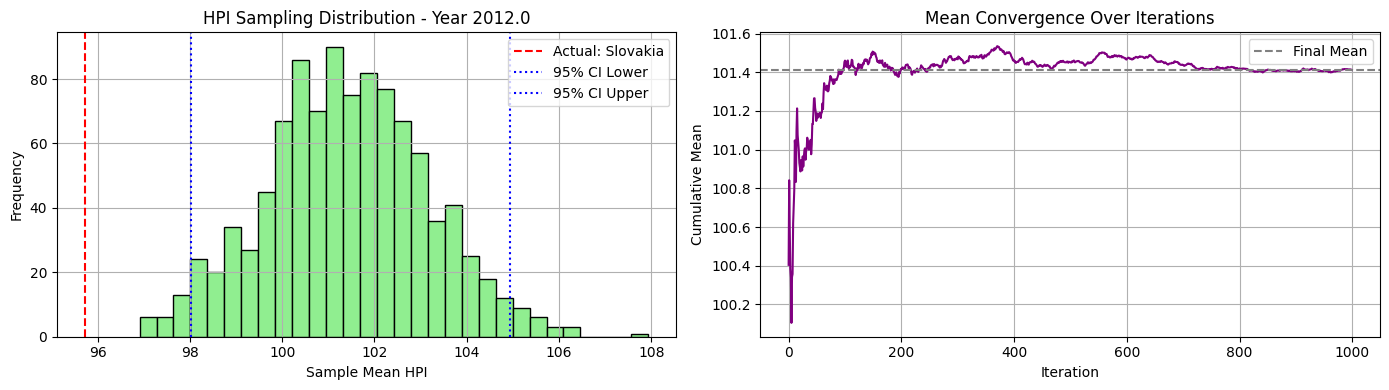

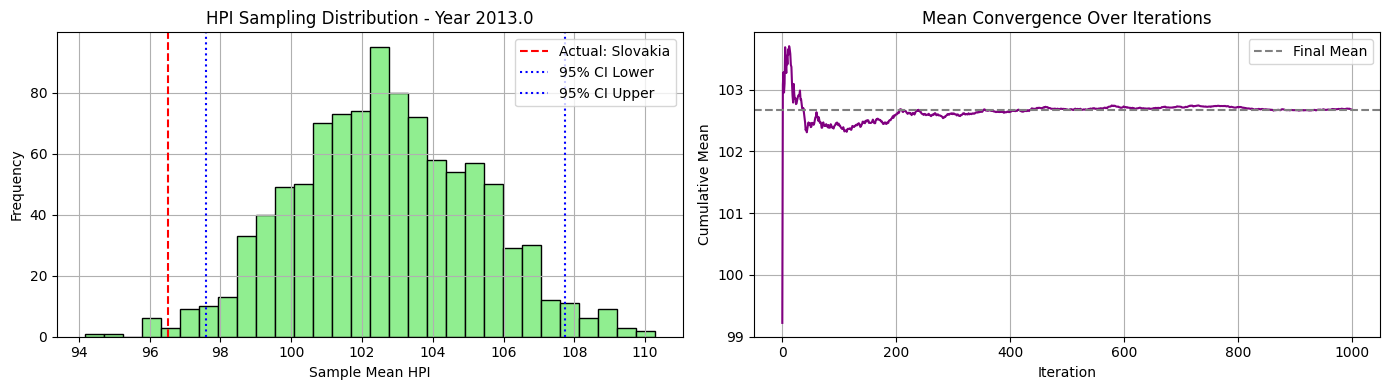

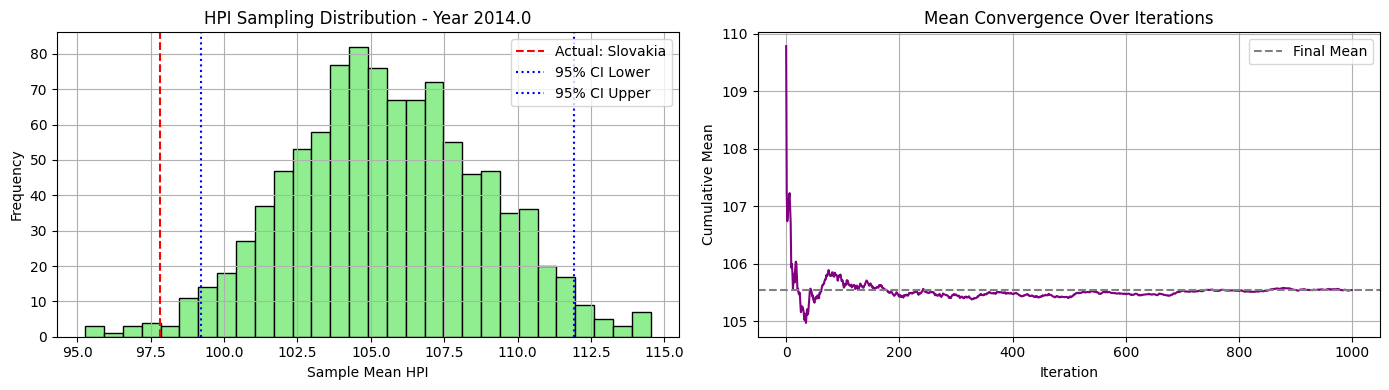

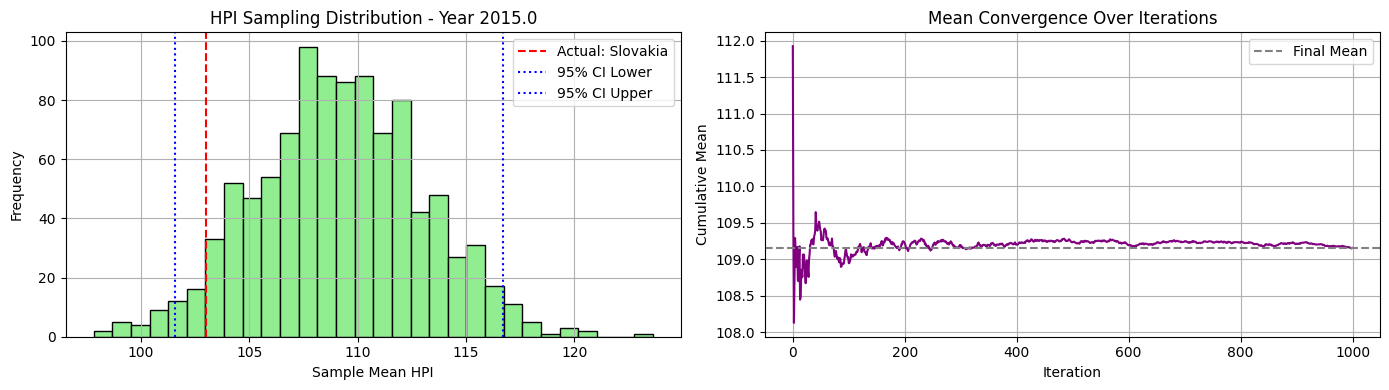

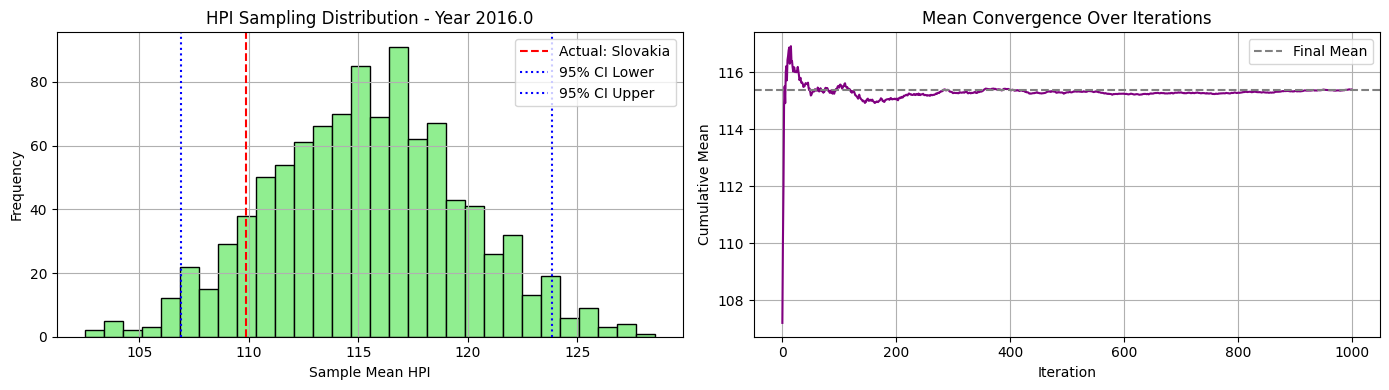

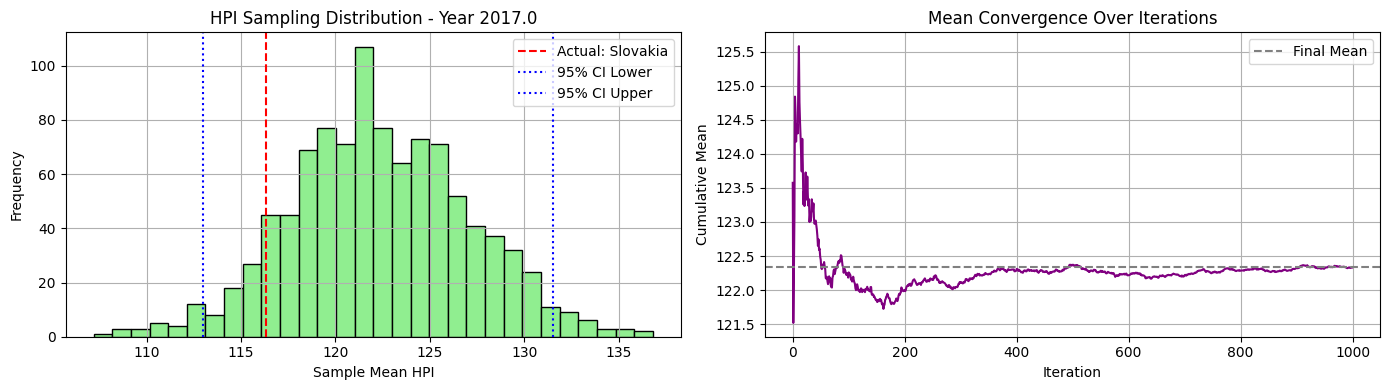

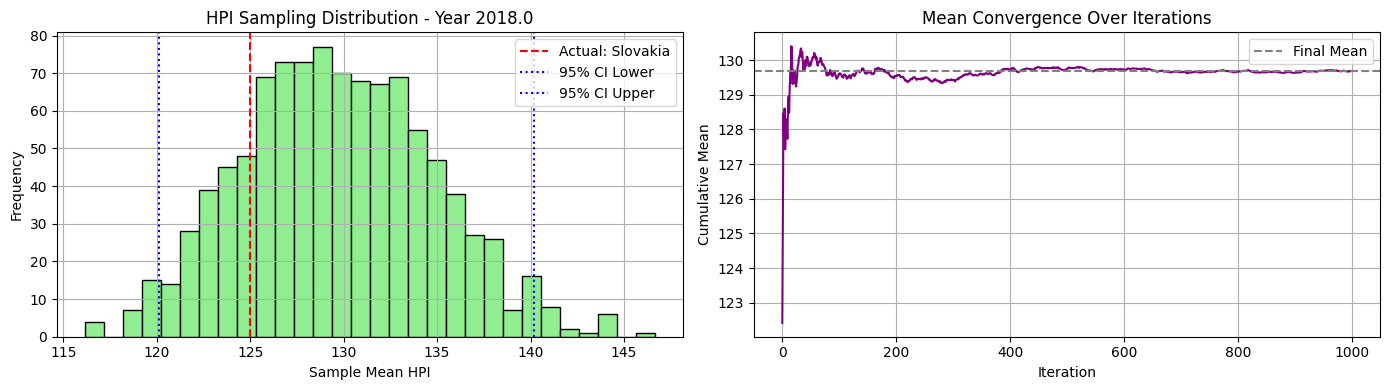

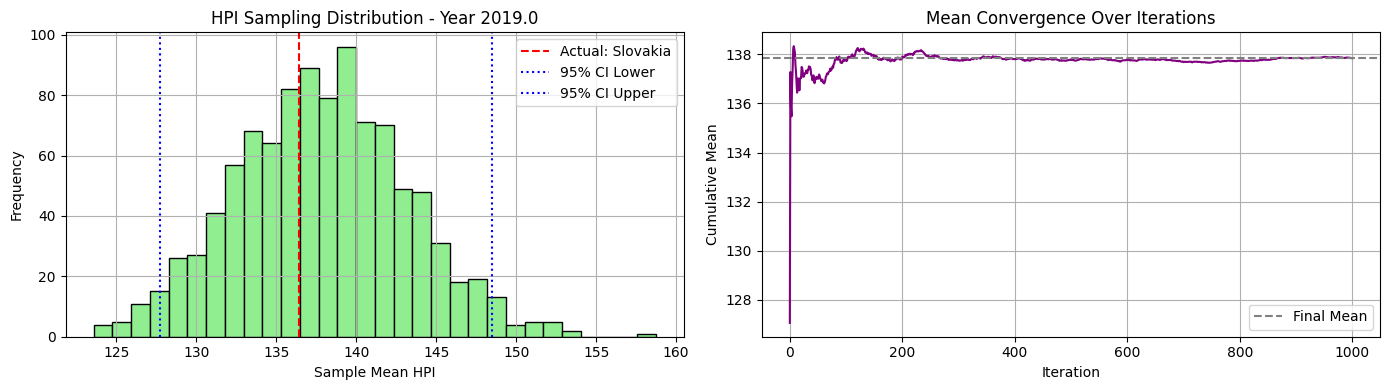

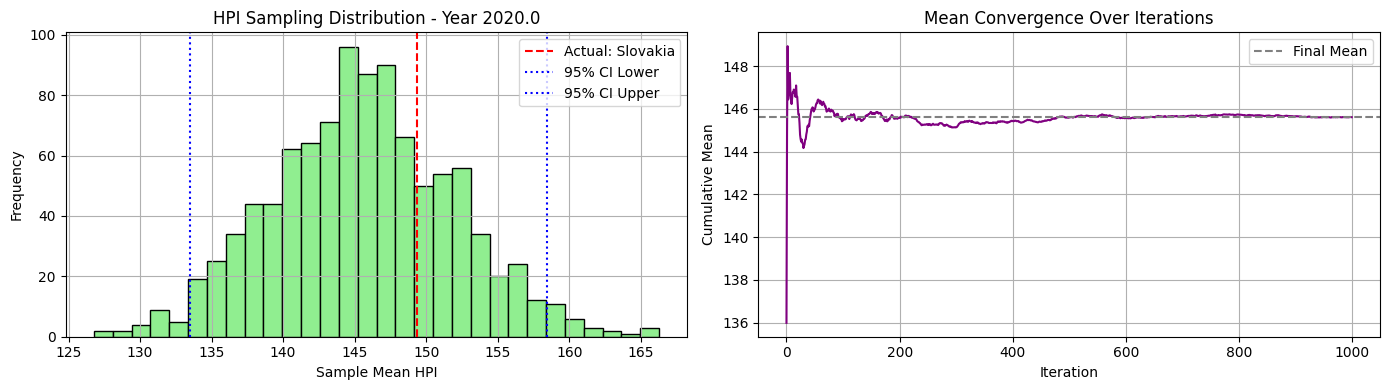

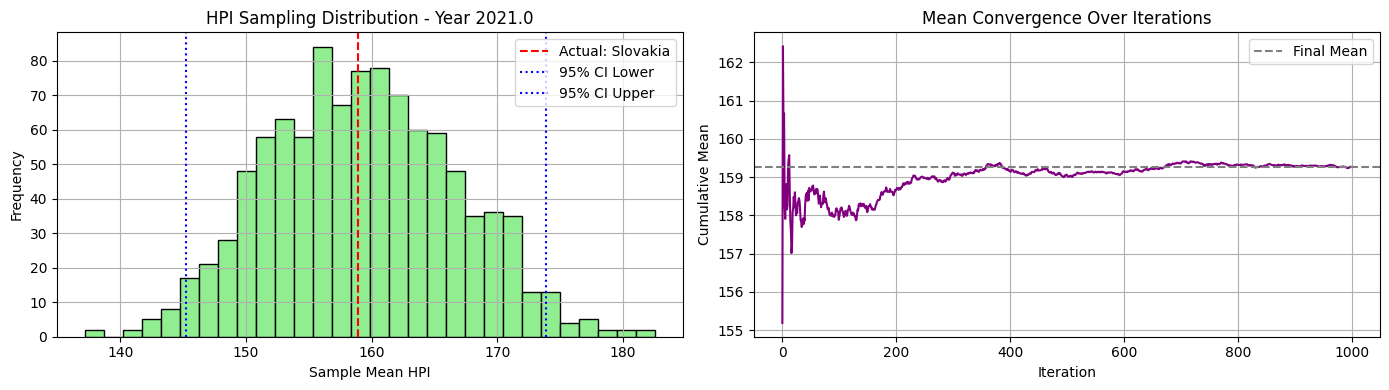

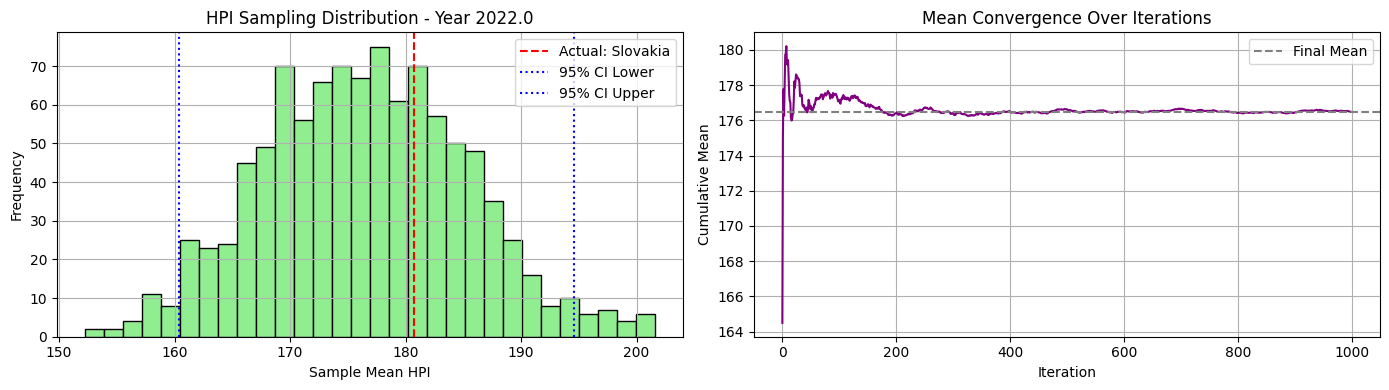

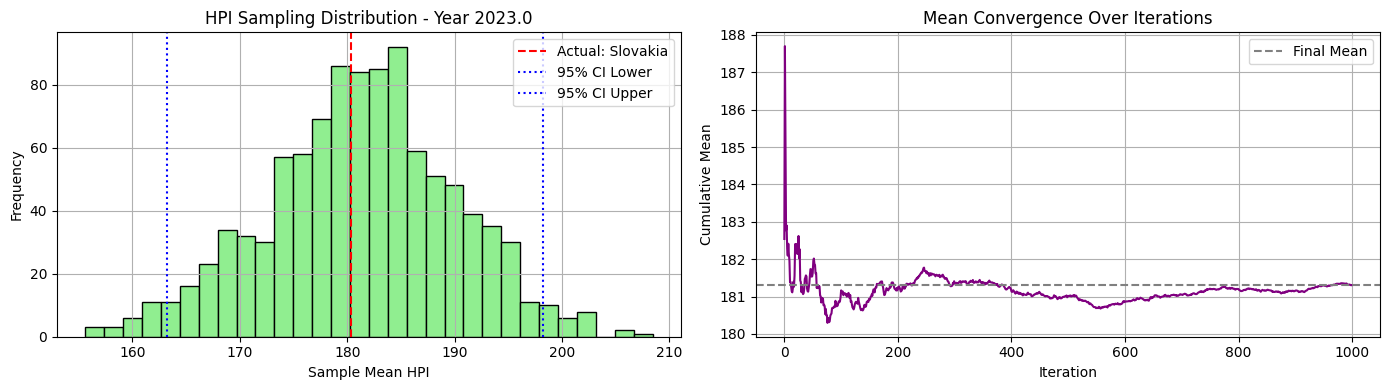

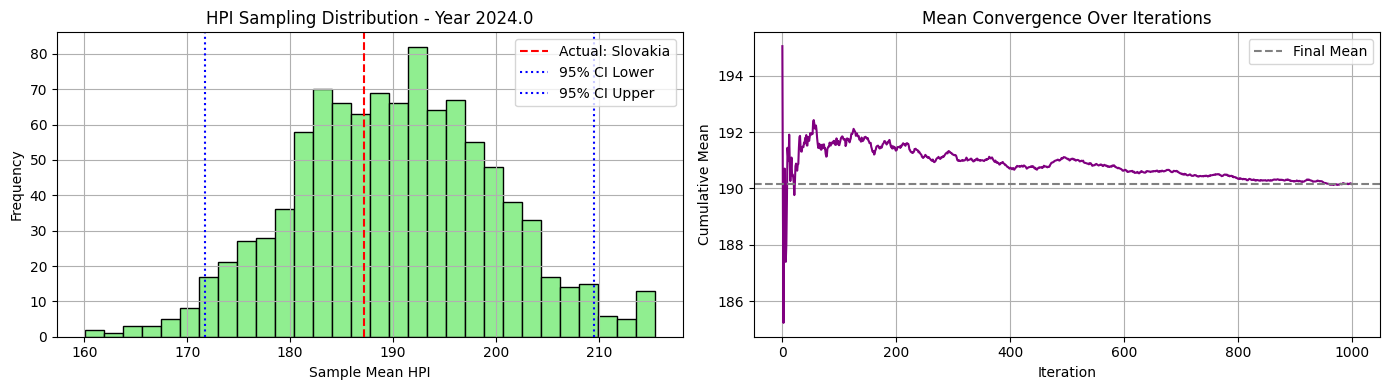

In [93]:
avg_mse_00_c3, avg_mae_00_c3, best_country_00_c3, yearly_bootstrap_means_00_c3, yearly_mean_00_c3 = evaluate_cluster_sampling_errors(df_hpi_winsorized, final_pca2_c3, cluster_id=0)

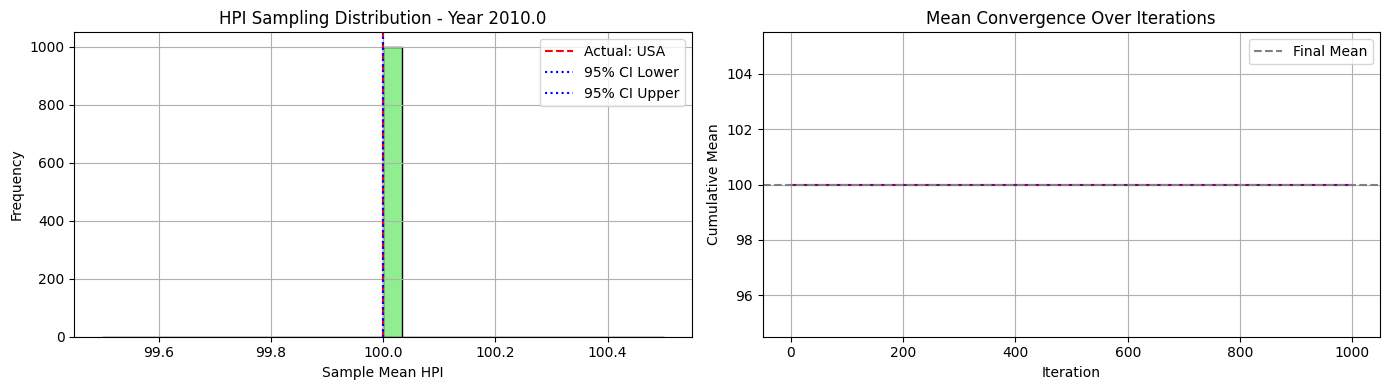

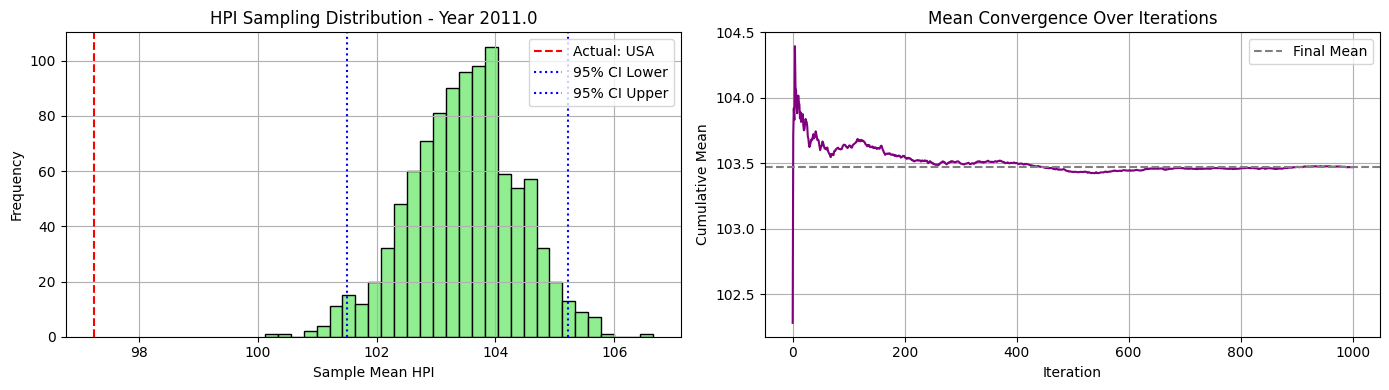

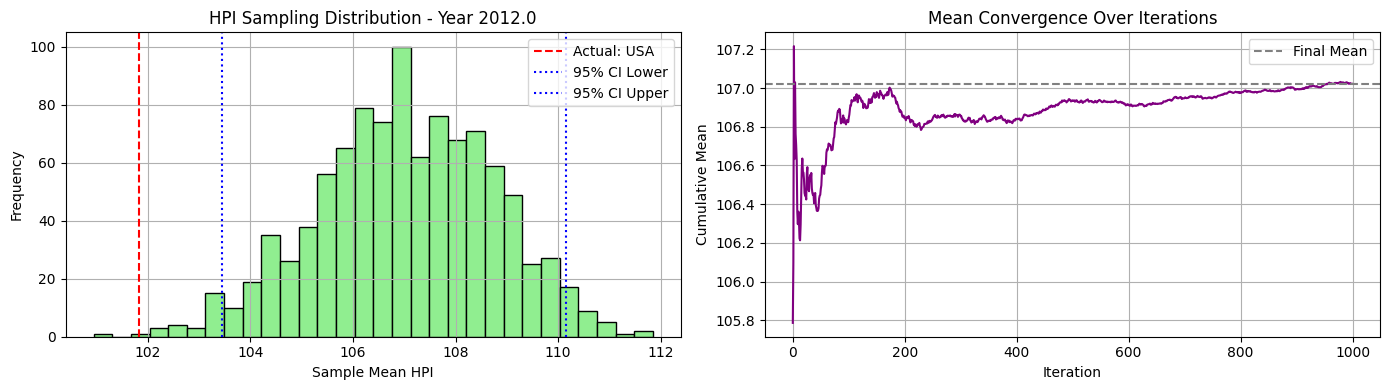

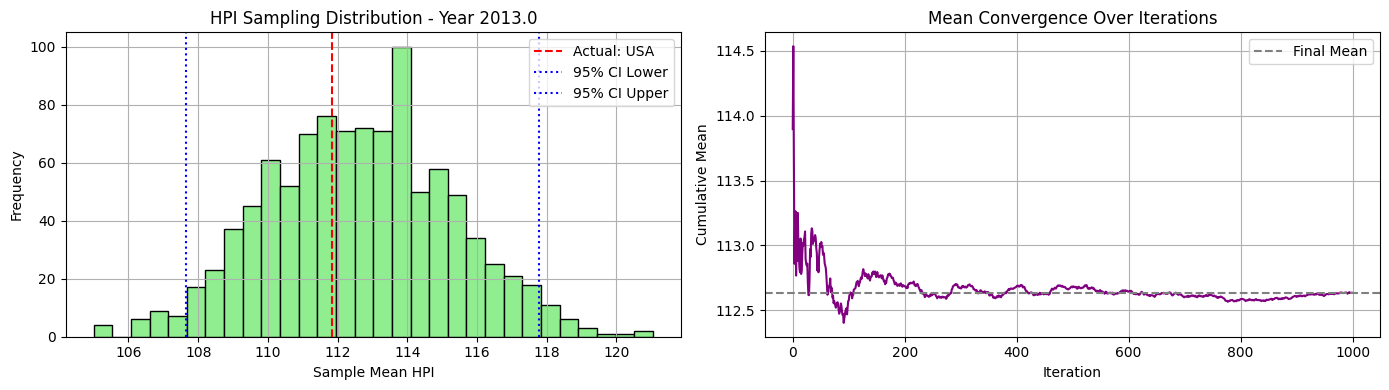

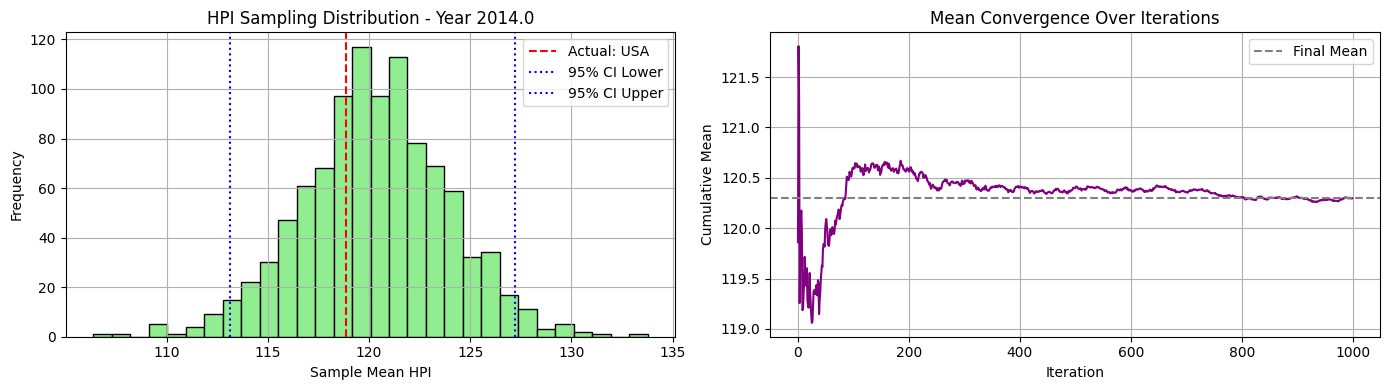

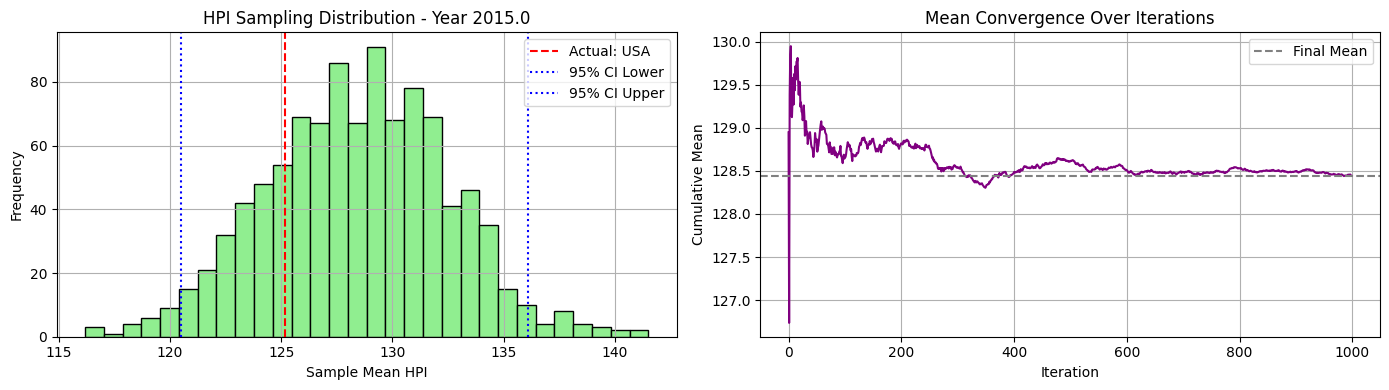

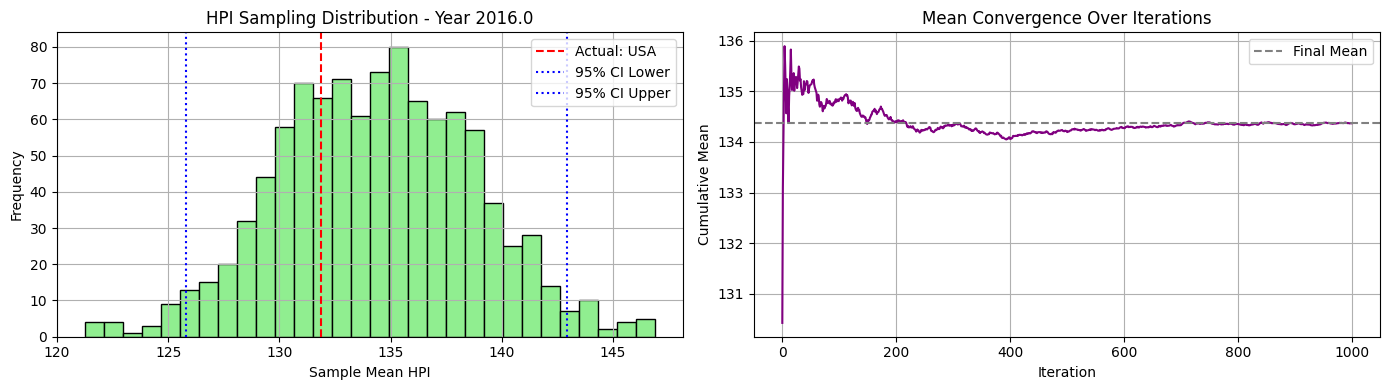

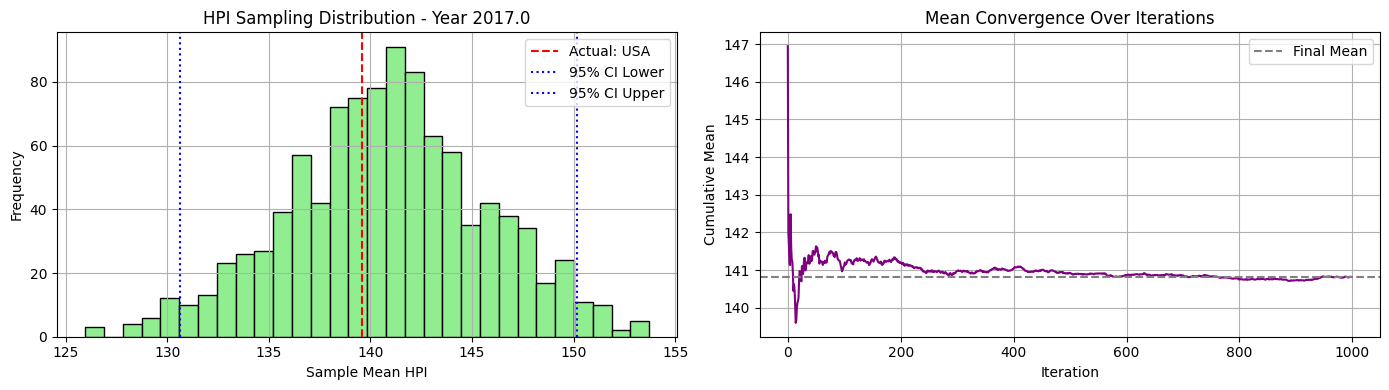

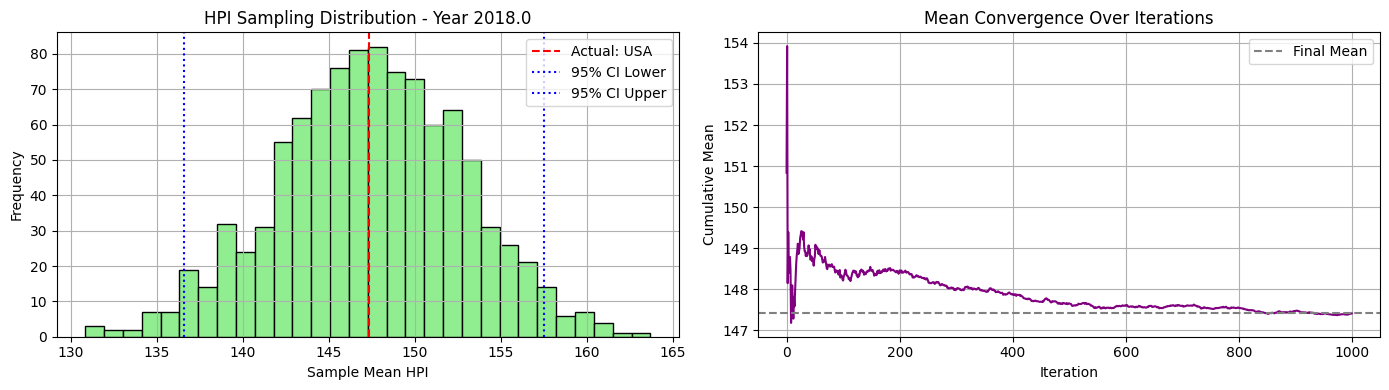

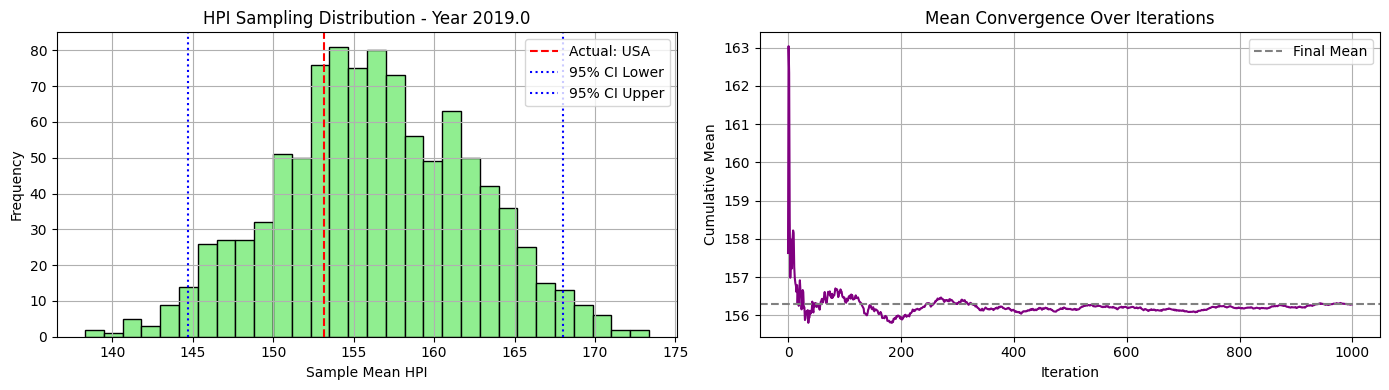

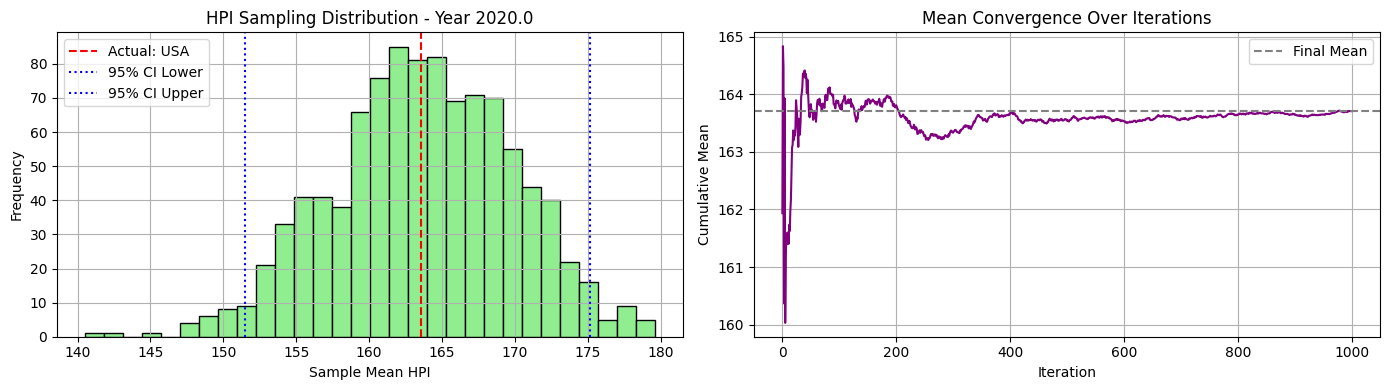

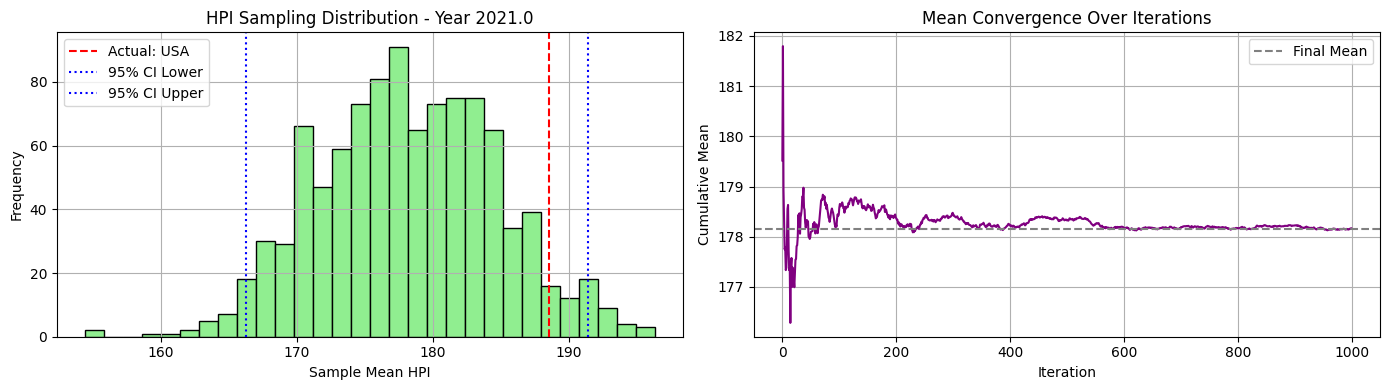

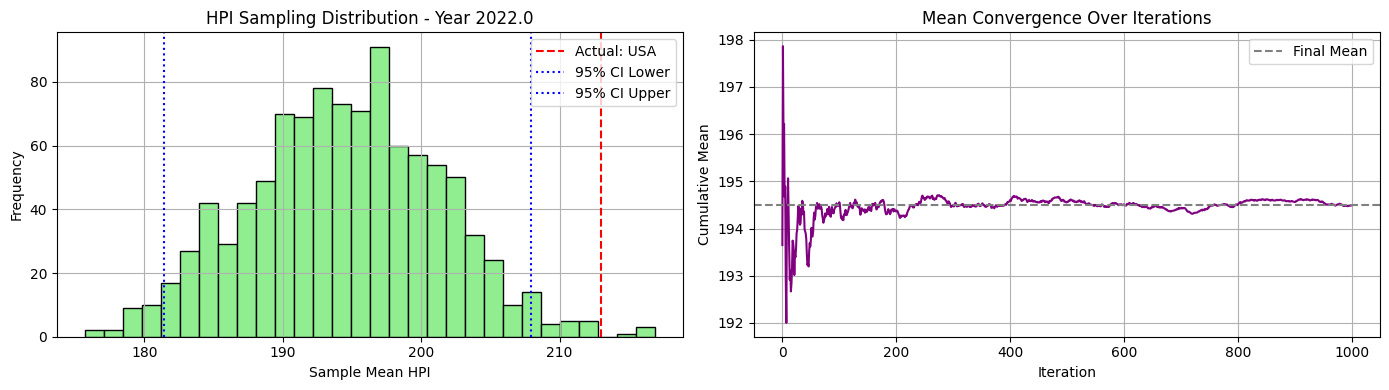

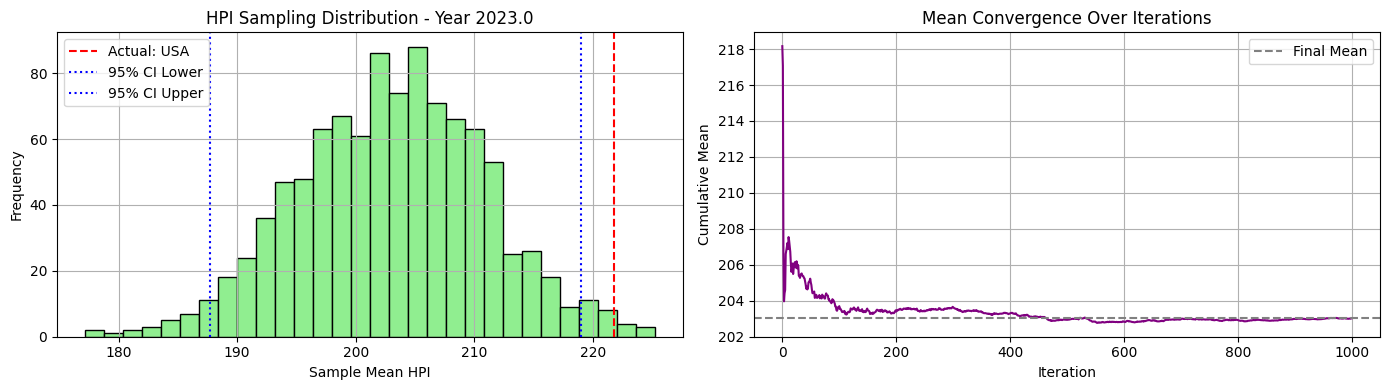

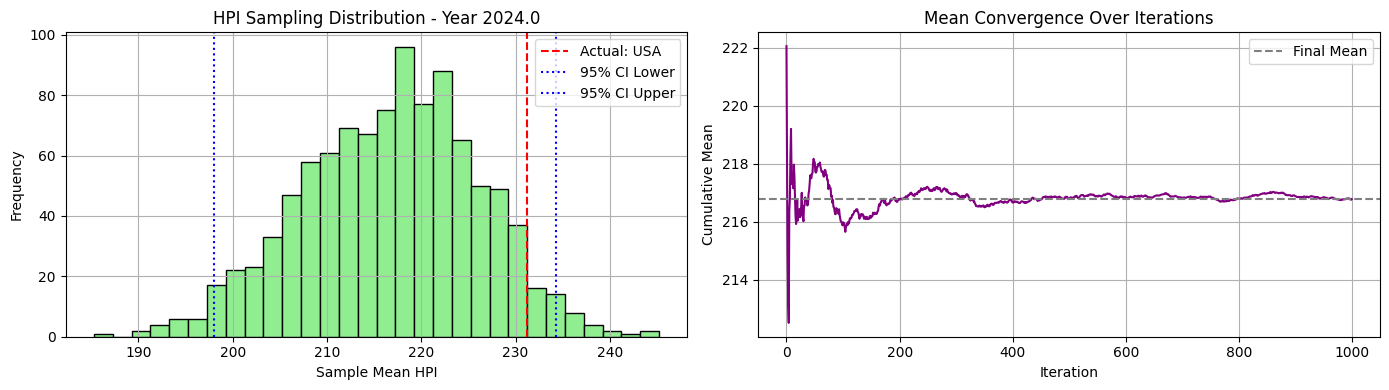

In [94]:
avg_mse_01_c3, avg_mae_01_c3, best_country_01_c3, yearly_bootstrap_means_01_c3, yearly_mean_01_c3 = evaluate_cluster_sampling_errors(df_hpi_winsorized, final_pca2_c3, cluster_id=1)

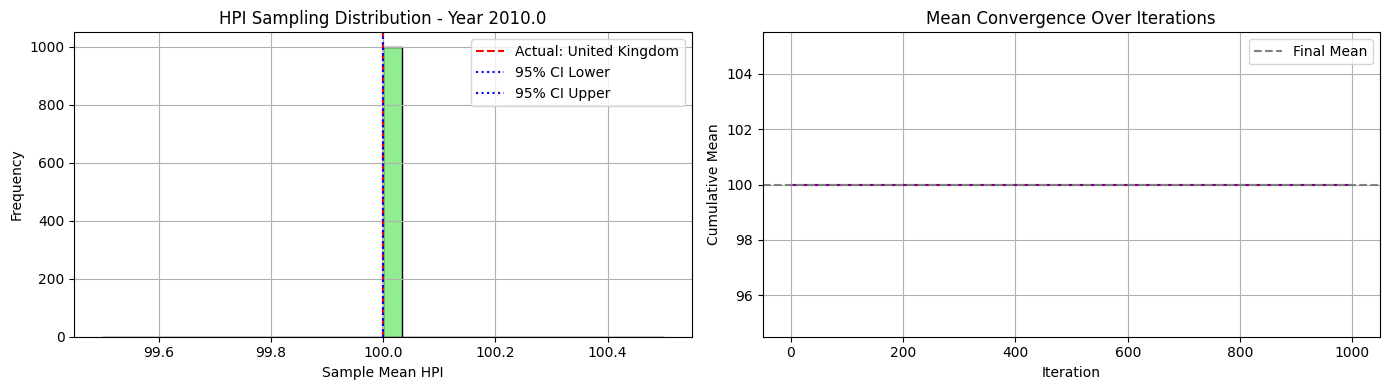

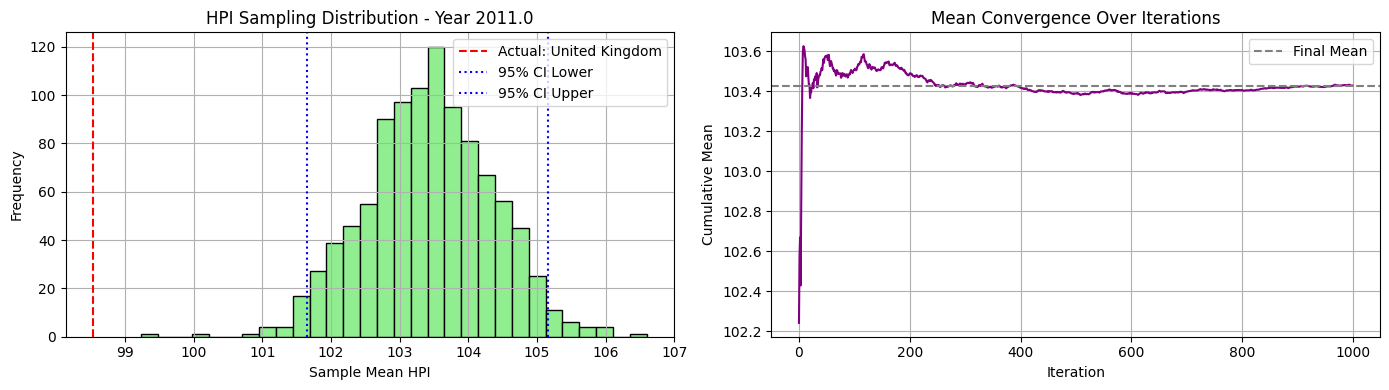

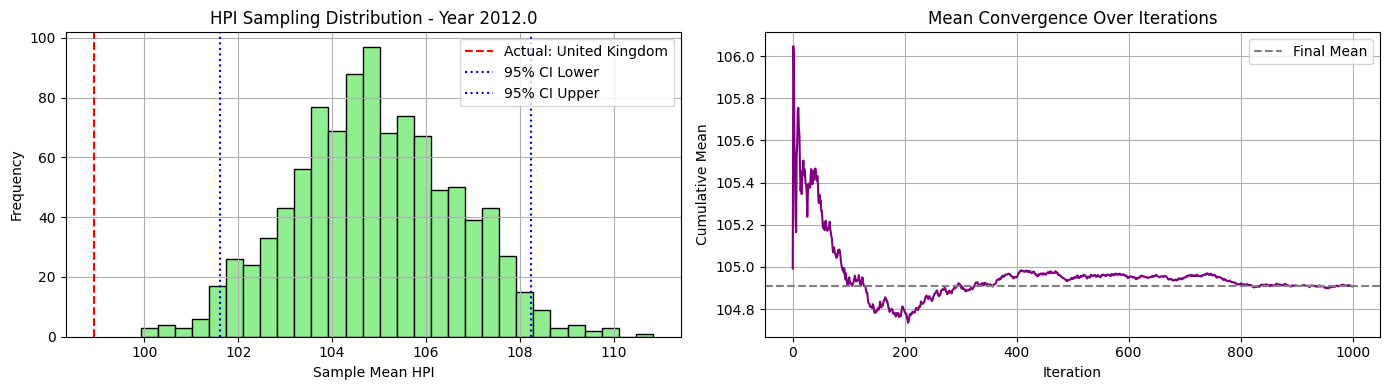

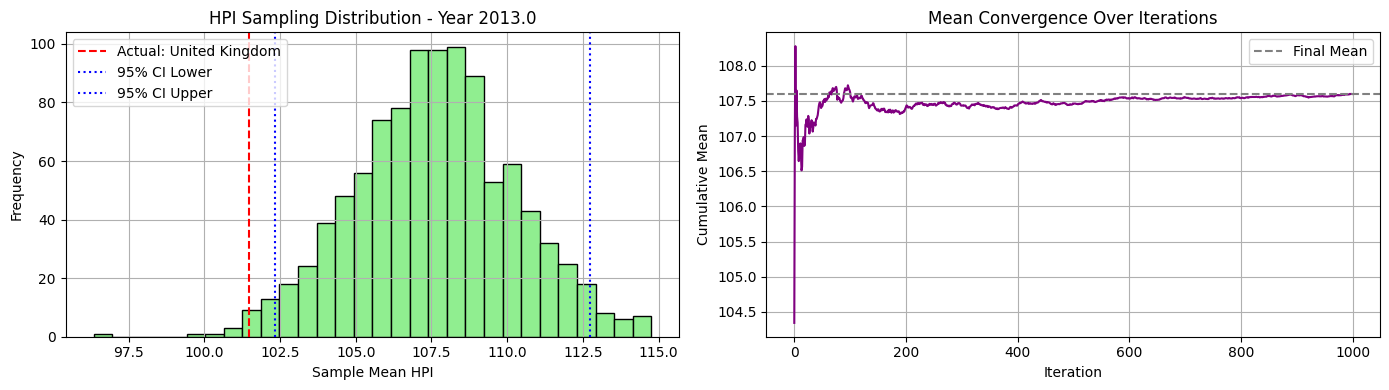

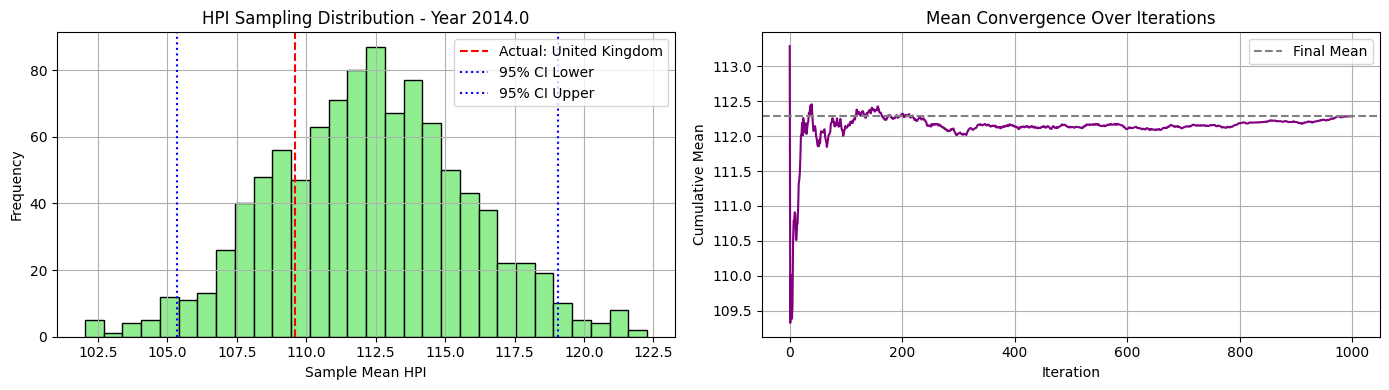

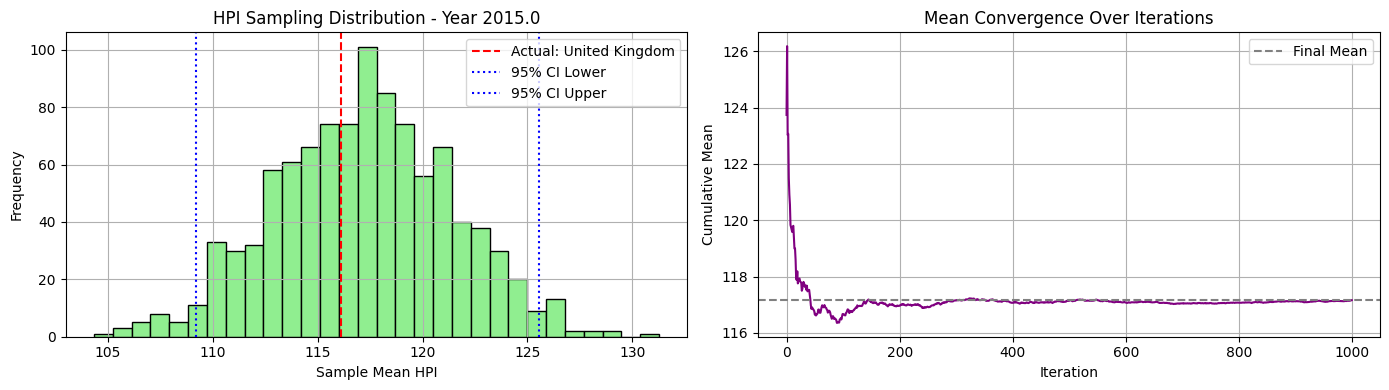

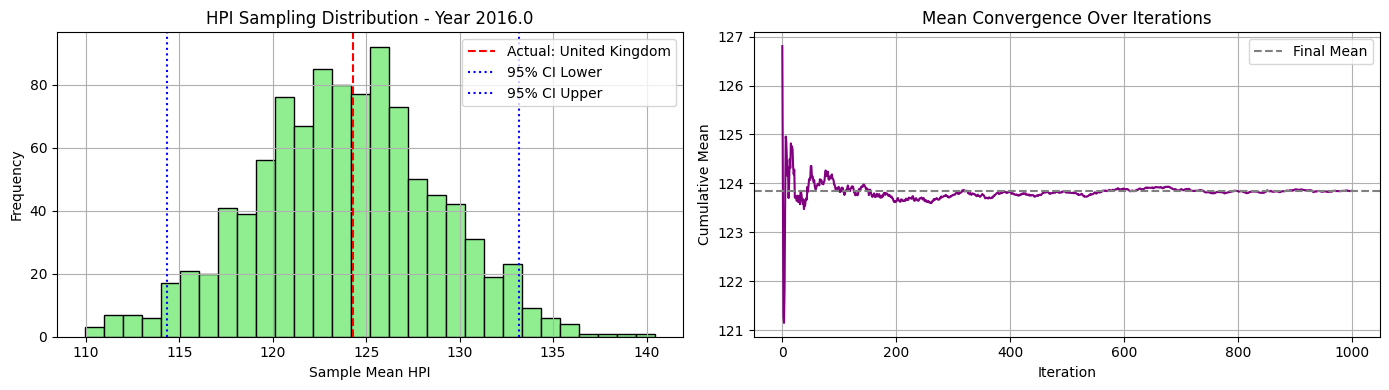

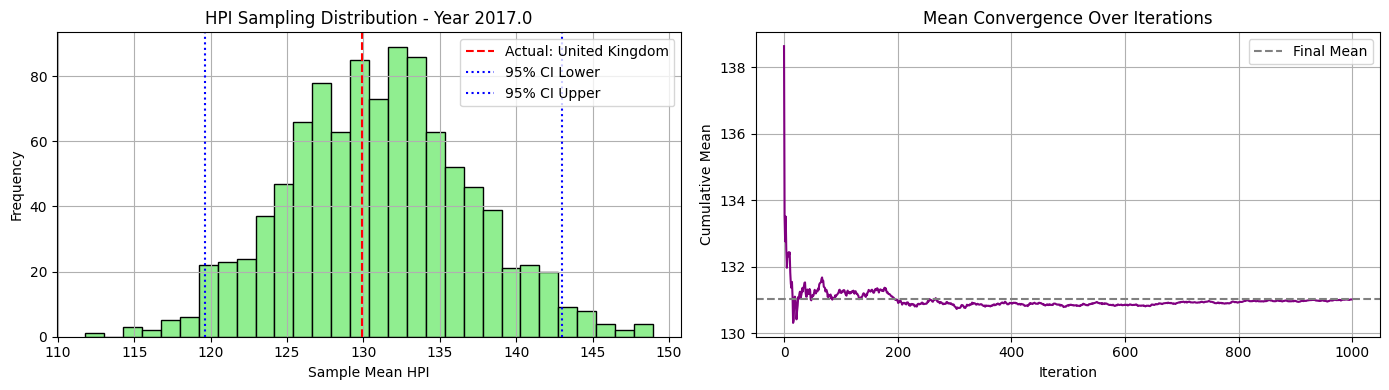

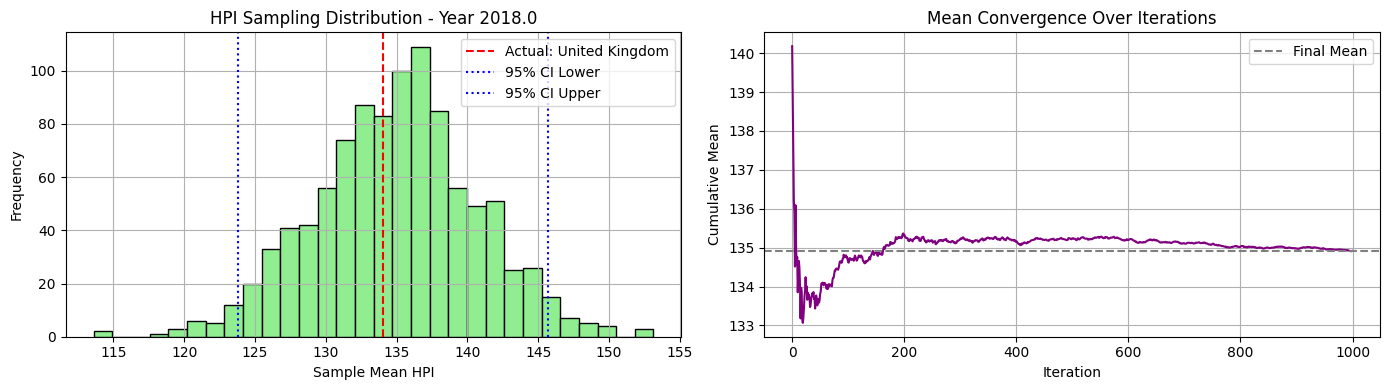

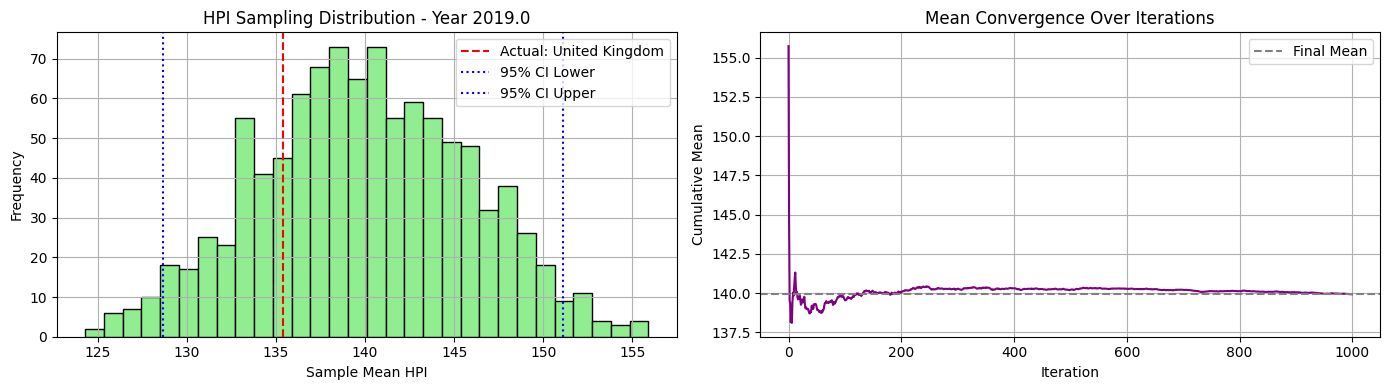

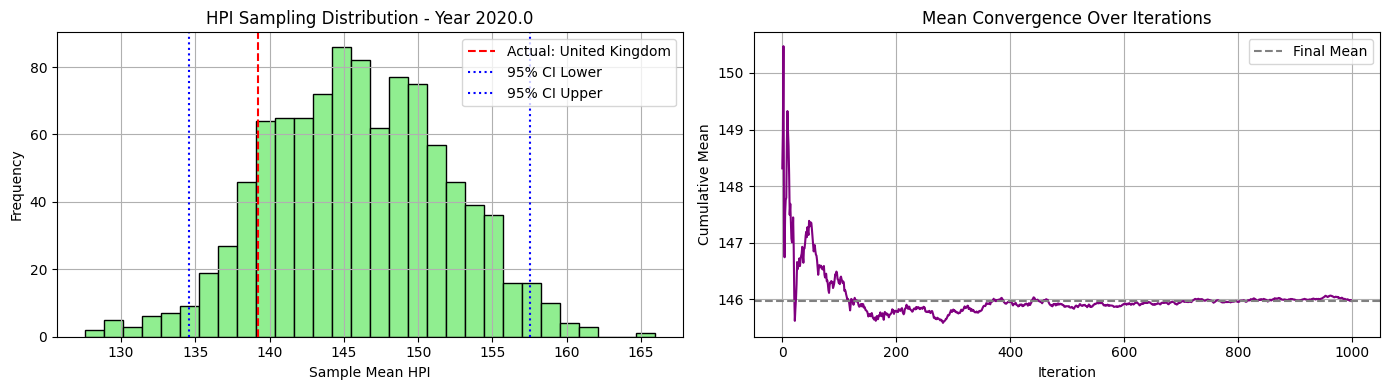

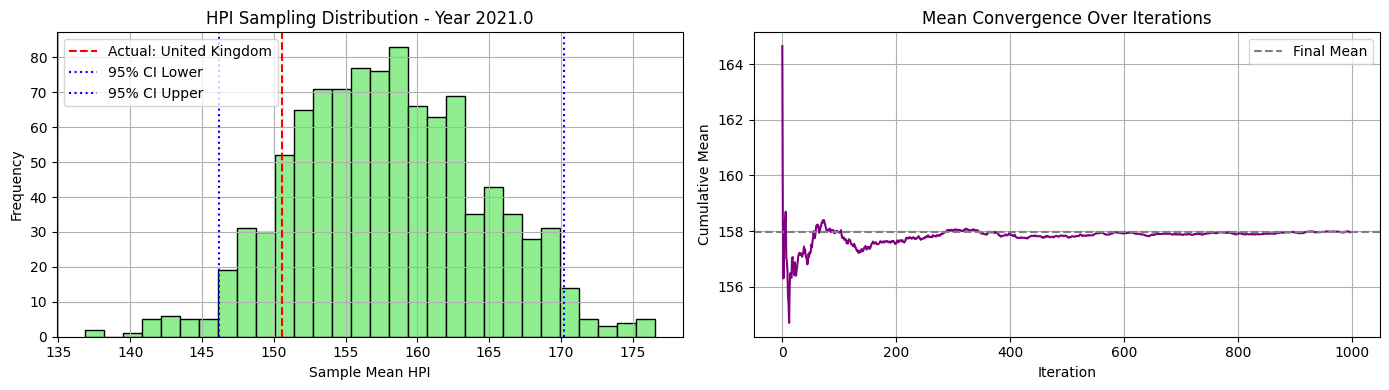

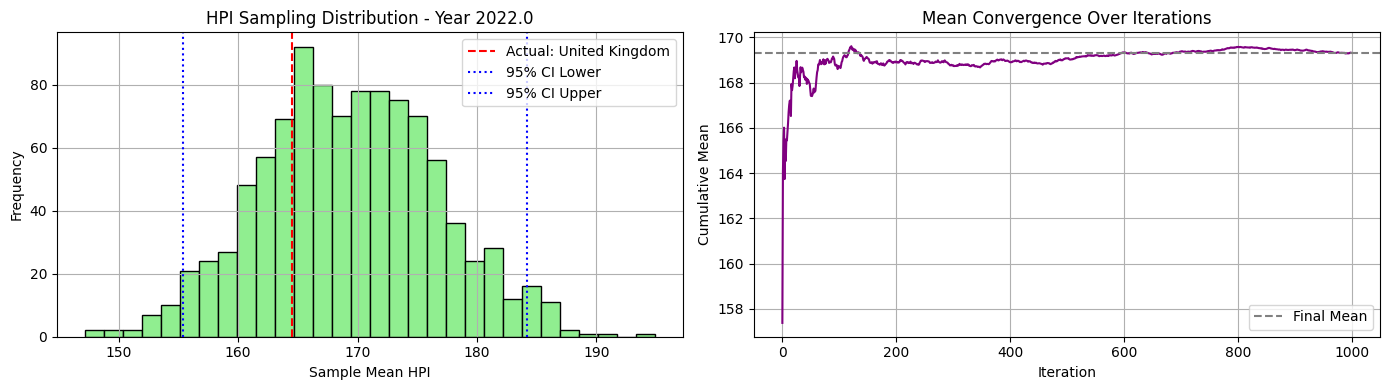

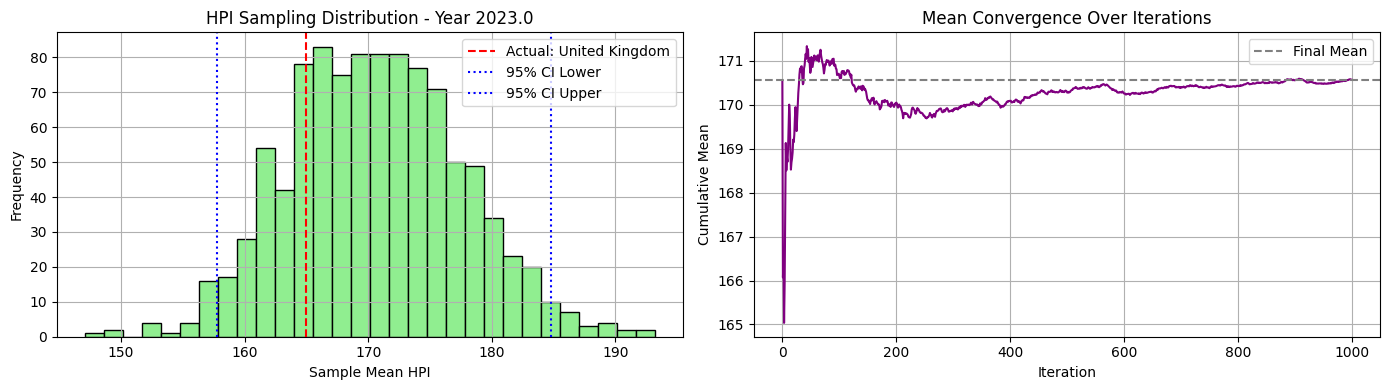

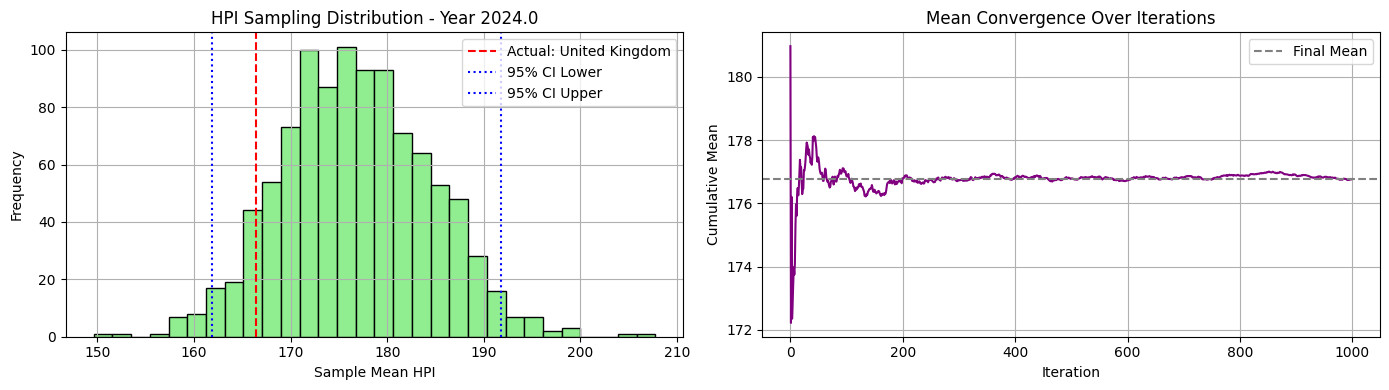

In [95]:
avg_mse_02_c3, avg_mae_02_c3, best_country_02_c3, yearly_bootstrap_means_02_c3, yearly_mean_02_c3 = evaluate_cluster_sampling_errors(df_hpi_winsorized, final_pca2_c3, cluster_id=2)

### Compute Metrics

In [96]:
errors3 = {
    'cluster_0': [avg_mse_00_c3, avg_mae_00_c3],
    'cluster_1': [avg_mse_01_c3, avg_mae_01_c3],
    'cluster_2': [avg_mse_02_c3, avg_mae_02_c3]
}

In [97]:
# Convertir a DataFrame
df_errors3 = pd.DataFrame.from_dict(errors3, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors3 = df_errors3.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors3)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1012.2848      23.1969
cluster_1     922.0112      22.8497
cluster_2     835.3966      21.4571


In [98]:
variances3 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, final_pca2_c3)
for cluster_id, var in variances3.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 952.2940
Cluster 1: Avg HPI Variance = 851.6158
Cluster 2: Avg HPI Variance = 791.5040


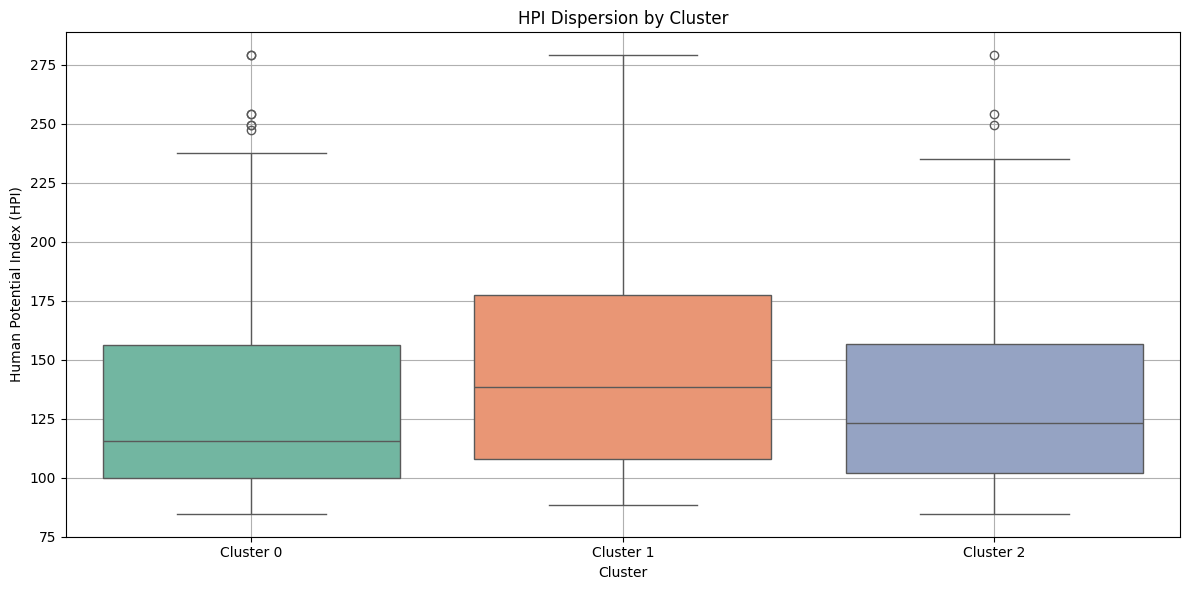

In [99]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, final_pca2_c3)

In [100]:
iqr_percent3= percentage_points_within_iqr_by_cluster(df_hpi_winsorized, final_pca2_c3)
print(iqr_percent3)

{np.int32(0): np.float64(56.08), np.int32(1): np.float64(56.92), np.int32(2): np.float64(50.88)}


### Log performance

In [101]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,NaN,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,NaN,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,NaN,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN
8,kmeans_++_2c_h2_2delete_countries_exclude,2025-09-18 17:00,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420313,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Delete Countries x2, Winsorization x4, rounding",Winsorization x4,bootstrap,None,51.0,874.340400,21.932350,hypothesis_test_026,NaN,None,955.31,722.29,NaN,NaN,49.0,53.0,NaN,NaN
9,kmeans_++_2c_h2_2delete_pca_countries_exclude,2025-09-20 22:43,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.563596,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x4, rounding",Winsorization x4,bootstrap,None,51.0,877.778200,21.621850,hypothesis_test_29,0.74,"(0.66, 0.08)",892.71,793.60,NaN,NaN,51.0,51.0,NaN,NaN


In [102]:
new_entry3 = {
    'experiment_name': 'kmeans_++_3c_h2_2delete_pca_countries_exclude',
    'experiment_date': '2025-09-20 22:50',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 51,
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score_c3_pca2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'outliers_handling_clustering': 'Winsorization x6',
    'used_all_variables_for_clustering': "['gdp', 'inflation', 'agr_land', 'livestock_prod']",
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x4, rounding',
    'outliers_handling_sampling': 'Winsorization x4',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 51,
    'mse_score': df_errors3['Average MSE'].mean(),
    'mae_score': df_errors3['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_29',
    'pca_ratio_sum': sum_var_expl_sum,
    'pca_ratio_values': tuple_var_expl_pca,
    'Variance_Cluster_0': round(float(variances3[0]),2),
    'Variance_Cluster_1': round(float(variances3[1]),2),
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_percent3[0]),
    'IQR_Count_Cluster_1':int(iqr_percent3[1]),
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [103]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_13664\1527126143.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry3])], ignore_index=True)


In [104]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [105]:
log_df.to_parquet("../data/log_performance/new_log_performance.parquet")

In [106]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,NaN,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,NaN,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
2,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,NaN,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
3,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,NaN,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0
4,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1118.876100,23.644450,hypothesis_test_013,NaN,None,1177.08,975.18,NaN,NaN,54.0,51.0,NaN,NaN
5,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1145.655433,24.226533,hypothesis_test_013,NaN,None,1257.22,1050.94,927.59,NaN,53.0,56.0,50.0,NaN
6,kmeans_++_2c_h2_countries_exclude,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.428486,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1131.624450,24.274950,hypothesis_test_018,NaN,None,1024.42,1152.36,NaN,NaN,49.0,49.0,NaN,NaN
7,kmeans_++_2c_h2_4delete_countries_exclude,2025-09-17 15:31,None,49,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420890,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'livestock_pr...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,49.0,860.984600,21.624550,hypothesis_test_024,NaN,None,988.52,661.65,NaN,NaN,49.0,49.0,NaN,NaN
8,kmeans_++_2c_h2_2delete_countries_exclude,2025-09-18 17:00,None,51,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.420313,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation', 'agr_land', 'live